# Numerai Classic v6.0 ("Unity") — Deterministic Baselines A, E & Persistence (`NumeraiExtractions` + `BinSnappingEstimator`, `LagReversalEstimator` & `PersistenceEstimator`)

- **Data Loading (`data_utils.load_unity_numerai_data`)**: Resolves and downloads the Unity v6.0 Parquets using the official Kaggle clients (`kagglehub.dataset_download` and `kaggle.api.kaggle_api_extended.KaggleApi`) with `numerapi.NumerAPI` fallback, catching each library's actual exception classes (`KaggleApiHTTPError`, `UnauthenticatedError`, `CredentialError`, `NotFoundError`, `DataCorruptionError`, `BackendError`, `KaggleEnvironmentError`, `ColabEnvironmentError`, `kaggle.rest.ApiException`, `HTTPError`, `OSError`, `ValueError`).
- **Exploratory Data Analysis (`# EDA`)**: Lists available `TARGET_COL` and `feature_set` options from `features.json`, inspects `train_df.head(2)` / `validation_df.head(2)` and `info()`, plots era sizes over time (`groupby(ERA_COL)[TARGET_COL].size()`), overlays feature standard-deviation distributions across Train vs. Validation, and displays the top 10 features correlated with `TARGET_COL`.

---

### 1. Feature Extraction Parameters (`utils.NumeraiExtractions` — `estimator__extractor__*`)
- **`era_col`** (`[ERA_COL]`): Column name containing the sequential weekly time index (`'era'`).
- **`ticker_col`** (`[TICKER_COL]`): Column name containing the security identifier (`'numerai_ticker'`).
- **`target_col`** (`[TARGET_COL, 'target_cyrusd_20', 'target_teager2b_20']`): Target column used when ranking features by target correlation.
- **`year_horizon_filter`** (`[None, (1, 2, 3), (4, 5, 6), (7, 8, 9)]`): Restricts `fit()` variance and correlation estimation to specific 52-week training year buckets `(era - 1) // 52 + 1` (`None` uses all training years; never exposed as a model feature).
- **`variance_threshold`** (`[None, 0.02, 0.05, 0.10]`): Drops near-constant features whose training variance is $\le$ threshold via `sklearn.feature_selection.VarianceThreshold` (`None` keeps all features).
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`):
  - `None`: Skips correlation ranking and keeps original column order.
  - `'pandas_mean'`: Computes per-era Pearson correlation (`era_df.corrwith(era_target)`) and averages across eras.
  - `'numerai_mean'`: Computes official per-era `numerai_tools.scoring.numerai_corr` and averages across eras.
  - `'pearson'`: Global pooled Pearson correlation (`r_regression`) across all rows.
  - `'spearman'`: Global pooled Spearman rank correlation across all rows.
- **`abs_corr`** (`[True, False]`): `True` ranks features by $|\text{corr}|$ (strongest magnitude in either direction); `False` ranks by signed $\text{corr}$ (positive only first).
- **`top_k`** (`[None, 10, 20, 40]`): Keeps only the top $K$ highest-ranked features from the extractor (`None` keeps all features).
- **`feature_selection_percentile`** (`[None, 25.0, 50.0, 75.0, 100.0]`): Keeps the top percentage of ranked features (`None` keeps all features).
- **`sparse_selector`** (`[None, 'lasso', 'elasticnet']`) & **`sparse_alpha`** (`[0.001, 0.01, 0.1]` / `Real(1e-4, 1e-1, prior='log-uniform')`): Optional multivariate sparse feature selection via `sklearn.feature_selection.SelectFromModel` with `Lasso` or `ElasticNet` fitted strictly inside `fit()` (`None` disables).
- **`pca_n_components`** (`[None, 10, 20, 40]` / `0.90`): Optional `sklearn.decomposition.PCA` compression fitted strictly inside `fit()` and quantized to `0..4` `int8` bins in `transform()` to reduce feature exposure without dropping features (`None` disables).
- **`quantize_scope`** (`['era', 'train_fit', 'global']`) & **`quantize_strategy`** (`['zscore', 'quantile']`): Controls how continuous derived features are quantized into `0..4` `int8` bins (`'era'` = leak-free within-era cross-sectional quantization; `'train_fit'` = frozen `StandardScaler` fitted strictly on training data in `fit()`; `'global'` = legacy full-array quantization; `'zscore'` = z-score rounding vs. `'quantile'` = `KBinsDiscretizer` quantile edges).
- **`sequence_top_n`** (`[4, 2, 8]`): Number of top-ranked features expanded by rolling-era, lag-diff, and per-ticker sequence extractors.
- **`missing_fill_value`** (`[2.0, 0.0, 4.0, 'mean', 'median', 'era_mean', 'era_median']`):
  - `2.0`, `0.0`, `4.0`, `'mean'`, `'median'`: Imputes missing values via `sklearn.impute.SimpleImputer` (`2.0` is the neutral middle bin of Numerai's `0..4` scale).
  - `'era_mean'` / `'era_median'`: Fills missing values with each feature's within-era cross-sectional mean or median.
- **`feature_groups`** (`unity_feature_groups` on `NumeraiExtractions`, `None` if no thematic groups exist in `feature_metadata['feature_sets']`; omitted from CV search spaces to prevent console log bloat) & **`basic_group_stats`** (`[None, 'mean', 'std', 'skew', 'mean|std', 'mean|skew', 'std|skew', 'mean|std|skew']`): Computes leak-free row-wise summary statistics (`mean`, `std`, `skew` quantized to `0..4` bins) across real Unity v6.0 feature groups or built-in thematic prefixes (`None` disables).
- **`fourier_period_eras`** (`[52, 26, 13]`): Cycle length in eras (52 = annual, 26 = semi-annual, 13 = quarterly) used by `fourier_order`.
- **`fourier_order`** (`[None, 1, 2, 3]`): Sole cyclical seasonality encoding — adds smooth $\sin(2\pi k \cdot \text{era} / P)$ and $\cos(2\pi k \cdot \text{era} / P)$ harmonics for $k=1..\text{fourier\_order}$ quantized to `0..4` bins (`None` disables).
- **`include_rolling_era`** (`[False, True]`) & **`rolling_era_windows`** (`[(4, 12), (2, 6, 12), (4, 8, 16)]`): When `include_rolling_era=True`, computes causal rolling era means over each window length $W$ in `rolling_era_windows` for the top correlated features, quantized to `0..4` bins.
- **`include_lag_diff`** (`[False, True]`) & **`era_lag_scales`** (`[(1, 2, 4), (1, 2, 4, 8), (2, 4, 8)]`): When `include_lag_diff=True`, computes causal era-to-era lag differences ($\bar{x}_e - \bar{x}_{e-k}$) for each lag step $k$ in `era_lag_scales`, quantized to `0..4` bins.
- **`ticker_features`** (`[None, 'rolling_mean', 'momentum_diff', 'weeks_since_high', 'rolling_rank', 'weeks_since_change', 'expanding_stats', 'raw_lags', 'rolling_mean|momentum_diff', 'rolling_mean|momentum_diff|rolling_rank', 'expanding_stats|raw_lags', 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags']`), **`ticker_windows`** (`[(4, 12), (2, 6, 12)]`), & **`ticker_lag_steps`** (`[None, (1, 2), (1, 2, 4)]`): Computes causal per-ticker time-series features (`rolling_mean`, `momentum_diff`, vectorized `weeks_since_high`, `rolling_rank`, vectorized `weeks_since_change`, `expanding_stats` [`expanding().mean()/min()/max()`], and `raw_lags` [`shift(k)` for $k \in$ `ticker_lag_steps`]) grouped strictly by `numerai_ticker` sorted chronologically by `era` (`None` disables).
- **`era_dispersion_features`** (`[None, 'mean', 'std', 'extreme_frac', 'mean|std', 'mean|extreme_frac', 'std|extreme_frac', 'mean|std|extreme_frac']`): Adds per-row cross-sectional mean (`'mean'`), standard deviation (`'std'`), and fraction of extreme `0`/`4` bins (`'extreme_frac'`) across selected features (`None` disables).

---

### 2. Shared Parent Estimator Parameters (`baseline_utils.BaseNumeraiEstimator` — `estimator__*`)
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`): How the estimator scores and weights post-extraction features against `TARGET_COL`.
- **`abs_corr`** (`[True, False]`): `True` selects top features by $|\text{corr}|$; `False` selects by signed $\text{corr}$.
- **`top_k`** (`[None, 10, 20, 40]`): Number of top post-extraction features used by the estimator (`None` uses all extracted features).
- **`era_weighting`** (`[None, 'equal_era', 'recency_linear', 'recency_exp']`):
  - `None`: Equal weight per row.
  - `'equal_era'`: Equal total weight per era ($1 / N_{\text{era}}$) so large eras do not dominate.
  - `'recency_linear'`: Linearly increases era weight from oldest ($0.5$) to newest ($1.5$).
  - `'recency_exp'`: Exponentially decays older eras by $\exp(-\text{recency\_decay} \cdot (e_{\max} - e))$.
- **`recency_decay`** (`Real(0.001, 0.020)`): Exponential decay rate per era when `era_weighting='recency_exp'`.
- **`prediction_transform`** (`[None, 'era_zscore', 'era_rank']`):
  - `None`: Returns raw model predictions.
  - `'era_zscore'`: Standardizes predictions to zero mean and unit variance within each era.
  - `'era_rank'`: Converts predictions to `[0, 1]` percentile ranks within each era.
- **`bias_correction`** (`[None, 'mean_residual']`): When `'mean_residual'`, records `mean(y_train - y_hat_train)` in `fit()` and adds it to predictions in `predict()` (`None` disables).

---

### 3. Child Baseline Estimator Parameters (`BinSnappingEstimator`, `LagReversalEstimator` & `PersistenceEstimator`)
- **Baseline A — `BinSnappingEstimator` (Map Matching Lookup Table)**:
  - **`n_bins`** (`[5, 3, 7]`): Number of discrete integer bins per feature (`5` matches Numerai's `0..4` bins).
  - **`smoothing`** (`[0.0, 25.0, 50.0, 100.0]` / `Real(0.0, 100.0)`): Empirical-Bayes shrinkage weight pulling sparse bin averages toward the global target mean ($\frac{\sum y + m \cdot \bar{y}}{N + m}$).
  - **`agg_mode`** (`['mean', 'corr_weighted']`): `'mean'` averages snapped bin predictions equally across selected features; `'corr_weighted'` weights each feature's bin lookup by $|\text{corr}_j|$.
- **Baseline E — `LagReversalEstimator` (Era Autocorrelation / PACF Sign & Shrinkage Rule)**:
  - **`lag`** (`[1, 2, 4, 6]` / `Integer(1, 6)`): Number of era steps $k$ used to compute each feature's era-level lag-$k$ serial dependence.
  - **`acf_mode`** (`['feature_mean', 'feature_corr']`): `'feature_mean'` computes lag-$k$ dependence on each feature's per-era mean series; `'feature_corr'` computes lag-$k$ dependence on each feature's per-era target-correlation series.
  - **`acf_metric`** (`['acf', 'pacf']`): `'acf'` uses lag-$k$ autocorrelation; `'pacf'` uses lag-$k$ partial autocorrelation (`statsmodels.tsa.stattools.pacf`).
  - **`acf_detrend`** (`[None, 'linear', 'constant']`): Detrends the era series via `scipy.signal.detrend` before computing $\text{ACF}(k)$/$	ext{PACF}(k)$ (`None` = raw series, `'linear'` = removes linear time trend, `'constant'` = subtracts series mean).
  - **`acf_threshold`** (`[-0.05, 0.0, 0.05]` / `Real(-0.20, 0.20)`): Cutoff threshold $\tau$ for sign inversion or continuous shrinkage.
  - **`sign_mode`** (`['hard', 'soft_threshold', 'tanh']`): `'hard'` applies $\pm 1$ sign flip around `acf_threshold`; `'soft_threshold'` applies continuous soft-thresholded shrinkage; `'tanh'` applies smooth $\tanh((\text{acf} - \tau)/0.05)$ shrinkage.
  - **`center_features`** (`[True, False]`): `True` centers each feature by its training mean before applying the signed correlation weights; `False` multiplies raw bin values.
- **Brownlee Persistence Baseline — `PersistenceEstimator` (Decoupled Per-Ticker Target Persistence / Zero-Rule)**:
  - **`ticker_col`** (`[TICKER_COL]`): Security identifier column (`'numerai_ticker'`).
  - **`persistence_mode`** (`['last', 'expanding_mean', None]`): `'last'` predicts each ticker's most recent settled training target; `'expanding_mean'` predicts each ticker's historical training target mean; `None` falls back to Brownlee's Zero-Rule baseline (global training target mean).
  - **`persistence_lag`** (`[4, 1, 2, 8, None]`): Minimum era lag required before a training target is treated as settled (`4` for 20-day targets; `None` uses all available training history).
  - **`smoothing`** (`[0.0, 10.0, 25.0, 50.0]` / `Real(0.0, 100.0)`): Shrinkage pulling ticker target history toward the global training mean (`0.0` or `None` = no shrinkage).

---

- **Evaluation (`utils.evaluate_numerai_predictions`)**: Reports official `numerai_tools.scoring.numerai_corr`, per-era `Spearman Correlation`, `Average Payout` (`(corrs / 0.2).clip(-1, 1)`), `Sharpe Ratio` (`corrs.mean() / corrs.std()`), `Mean Absolute Error (MAE)`, `Forecast Bias` (`mean(y_true - y_pred)`), `Directional Hit Rate` (sign agreement vs. `0.5`), `Era CORR Lag-1 ACF`, `Ljung-Box p-value` (`acorr_ljungbox`), `ARCH-LM p-value` (`het_arch`), `ADF Stationarity p-value` (`adfuller`), `Skewness`, `Excess Kurtosis`, `Jarque-Bera p-value`, `Max Drawdown`, and validation `Feature Exposure`.

In [1]:
import gc
import os
import sys
import json
import time
import warnings
import importlib
from pathlib import Path
from datetime import datetime

python_env_dir = Path(sys.executable).parent
library_bin_dir = python_env_dir / 'Library' / 'bin'
if library_bin_dir.is_dir() and str(library_bin_dir) not in os.environ.get('PATH', ''):
    os.environ['PATH'] = str(library_bin_dir) + os.pathsep + str(python_env_dir) + os.pathsep + os.environ.get('PATH', '')

import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
try:
    import seaborn as sns
except ImportError:
    sns = None
from IPython.display import display

warnings.filterwarnings('ignore')

# Local, Kaggle (/kaggle/input, /kaggle/usr/lib, /kaggle/working), & nested dataset path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir).lower() == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
if workspace_root not in sys.path:
    sys.path.insert(0, workspace_root)
if os.path.isdir(src_path) and src_path not in sys.path:
    sys.path.insert(0, src_path)

module_search_roots = [
    Path(workspace_root),
    Path('/kaggle/working'),
    Path('/kaggle/usr/lib'),
    Path('/kaggle/input'),
]
for search_root in module_search_roots:
    if not search_root.is_dir():
        continue
    for target_file in ('afml_utils.py', 'data_utils.py', 'utils.py', 'baseline_utils.py'):
        for found_path in search_root.rglob(target_file):
            parent_dir = str(found_path.parent)
            if parent_dir not in sys.path:
                sys.path.insert(0, parent_dir)

from pandas.plotting import autocorrelation_plot
from scipy.stats import spearmanr
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from statsmodels.graphics.gofplots import qqplot

from numerai_tools.scoring import numerai_corr

try:
    import skopt
    from skopt import BayesSearchCV
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    BayesSearchCV = None
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

try:
    import wandb
except ImportError:
    wandb = None

try:
    import afml_utils
    import data_utils
    import utils
    import baseline_utils
except ModuleNotFoundError as import_err:
    mounted_kaggle_inputs = [str(p) for p in sorted(Path('/kaggle/input').iterdir())] if Path('/kaggle/input').is_dir() else []
    raise ModuleNotFoundError(
        f"{import_err}. Could not locate data_utils.py / utils.py / baseline_utils.py in "
        f"workspace_root={workspace_root}, /kaggle/working, /kaggle/usr/lib, or /kaggle/input "
        f"(mounted inputs: {mounted_kaggle_inputs}). "
        "On Kaggle, attach a Dataset or Utility Script containing src/data_utils.py, src/utils.py, and src/baseline_utils.py."
    ) from import_err
importlib.reload(afml_utils)
importlib.reload(data_utils)
importlib.reload(utils)
importlib.reload(baseline_utils)
from data_utils import (
    compute_per_ticker_timeseries_features,
    discover_and_fetch_v6_meta_or_benchmark,
    load_unity_numerai_data,
    load_unity_numerai_data_cached,
)
from utils import (
    NumeraiExtractions,
    build_experiment_setup,
    build_conditional_bayesian_spaces,
    build_quick_results_df,
    candidate_score,
    compute_r1399_churn_retention,
    compute_versioned_candidate_score,
    make_candidate_scorer,
    compute_eda_era_stationarity,
    compute_era_error_envelope,
    configure_error_binning,
    compute_feature_exposure,
    compute_feature_target_correlations,
    compute_per_era_mmc,
    compute_per_era_numerai_corr,
    compute_per_era_spearman_corr,
    deduplicate_param_grid,
    drop_constant_dims,
    evaluate_numerai_predictions,
    export_diagnostics_predictions,
    plot_era_error_envelope,
    plot_flight_residual_diagnostics,
    plot_stake_pnl_dashboard,
    plot_stake_pnl_monte_carlo,
    prepare_bayesian_space,
    quantize_to_5bins,
    reset_cv_metric_log,
    run_numereval_diagnostics,
    sharpe_ratio,
    build_live_staking_scenarios_df,
    compute_deflated_sharpe_ratio,
    compute_probabilistic_sharpe_ratio,
    simulate_live_staking_scenarios,
    simulate_stake_pnl,
    simulate_stake_pnl_monte_carlo,
    walk_forward_predict,
    CombinatorialPurgedEraCV,
    PurgedEraKFold,
    build_era_cv_splits,
    compute_clustered_mda,
    compute_drawdown_and_tuw,
    compute_hhi_concentration,
    compute_lo_adjusted_sharpe,
    compute_min_track_record_length,
    compute_pbo_cscv,
    compute_per_era_fnc,
    compute_strategy_risk,
    neutralize_predictions,
    purge_train_before_validation,
    summarize_afml_backtest_diagnostics,
)
from baseline_utils import (
    BaseNumeraiEstimator,
    BinSnappingEstimator,
    LagReversalEstimator,
    PersistenceEstimator,
    configure_extraction_cache,
    run_baseline,
)

print('Imports loaded successfully')
print(f'workspace_root={workspace_root} | SKOPT_AVAILABLE={SKOPT_AVAILABLE}')

Imports loaded successfully
workspace_root=/kaggle/working | SKOPT_AVAILABLE=True


# Setup

In [2]:
# --- Experiment Knobs (only things you actually change) ---
TARGET_COL = 'target'          # Training target (auto-sets horizon & embargo)
feature_set = 'small'          # 'small', 'medium', or 'all'
era_stride = 'auto'            # 'auto' (matches target horizon: 12 for 60d, 4 for 20d) or explicit int (1, 2, 4, 12)

baseline_mode = 'persistence'          # 'baseline_a', 'baseline_e', 'persistence', 'both', 'all'
search_mode = 'bayes'          # 'grid' or 'bayes'
score_version = 'v1_skepta'    # 'v0_default', 'v1_skepta', or 'v2_skepta_mmc'
eval_mode = 'both'             # 'static', 'walk_forward', or 'both'
cv_strategy = 'timeseries'   # 'timeseries', 'purged_kfold' (AFML Ch. 7), or 'cpcv' (AFML Ch. 12)
n_splits = 1
cv_split = 0.8                 # Chronological CV train/test split ratio (used when n_splits == 1)
downsample_mode = 'within_era'         # None, 'within_era', 'recent', 'earliest', 'uniform', or 'random_eras'
downsample_frac = 0.1          # Fraction of strided training data to keep in (0.0, 1.0]
val_downsample_mode = 'within_era'     # Validation: None (100%), 'same', 'within_era', 'recent', 'earliest', 'uniform', or 'random_eras'
val_downsample_frac = 0.1             # Fraction of validation data to keep in (0.0, 1.0] (None mirrors downsample_frac)
n_iter = 37
n_jobs = 1                    # Use 1 for feature_set='all' to save RAM
save_results = True
error_bin_mode = 'pct'         # 'pct' (% error + zero-target tol) or 'abs' (raw residual bins)

setup_cfg = build_experiment_setup(
    target_col=TARGET_COL,
    feature_set=feature_set,
    era_stride=era_stride,
    model_tag='baselines_ae',
    baseline_mode=baseline_mode,
    search_mode=search_mode,
    score_version=score_version,
    eval_mode=eval_mode,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    n_iter=n_iter,
    n_jobs=n_jobs,
    save_results=save_results,
    error_bin_mode=error_bin_mode,
    workspace_root=workspace_root,
)
globals().update(setup_cfg)

Experiment: numerai_v6.0_all_eras_stride12_baselines_ae | baseline_mode=persistence | search_mode=bayes | cv_strategy=timeseries (cv_split=0.8) | ERA_COL=era | TARGET_COL=target | era_stride=12 (auto-matched to horizon=12) | horizon=12 | embargo=1 | downsample(train=within_era@0.10, val=within_era@0.10)


# Prep

In [3]:
_prep_t0 = time.perf_counter()
train_df, validation_df, feature_columns, feature_metadata = load_unity_numerai_data_cached(
    data_version=data_version,
    data_folder=data_folder,
    kaggle_dataset=kaggle_dataset,
    feature_set=feature_set,
    target_col=TARGET_COL,
    era_stride=era_stride,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    random_state=random_state,
    ticker_timeseries_features=ticker_timeseries_features,
    ticker_rolling_windows=ticker_rolling_windows,
    ticker_lag_steps=ticker_lag_steps,
    workspace_root=workspace_root,
    auto_download=True,
    use_numerapi_fallback=True,
    force_reload=force_reload_data_cache,
)
prep_elapsed_s = time.perf_counter() - _prep_t0
print(f'Loaded {len(feature_columns)} int8 features | train={train_df.shape} ({train_df[ERA_COL].nunique()} eras) | validation={validation_df.shape} ({validation_df[ERA_COL].nunique()} eras)')

Loaded 101 int8 features | train=(36159, 106) (70 eras) | validation=(265366, 106) (398 eras)


## Exploratory Data Analysis (EDA)

In [4]:
available_targets = list(feature_metadata.get('targets', [TARGET_COL]))
print(f'Available TARGET_COL options ({len(available_targets)}):', available_targets)
print('Available feature_set options:', {k: len(v) for k, v in feature_metadata.get('feature_sets', {}).items()})

print('\nTraining data:')
display(train_df.head(2))
print('Validation data:')
display(validation_df.head(2))
print('Training set info:')
train_df.info()
print('\nValidation set info:')
validation_df.info()

Available TARGET_COL options (24): ['target', 'target_raw_return_20', 'target_raw_return_60', 'target_factor_neutral_20', 'target_factor_neutral_60', 'target_factor_feat_neutral_20', 'target_factor_feat_neutral_60', 'target_camille_20', 'target_camille_60', 'target_sydney_20', 'target_sydney_60', 'target_irina_20', 'target_irina_60', 'target_alexandra_20', 'target_alexandra_60', 'target_colleen_20', 'target_colleen_60', 'target_jean_20', 'target_jean_60', 'target_eleven_4', 'target_eleven_20', 'target_eleven_60', 'target_jupiter_20', 'target_jupiter_60']
Available feature_set options: {'small': 101, 'medium': 351, 'all': 1040, 'signals': 23}

Training data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_41,feature_charisma_2,feature_charisma_5,feature_charisma_7,feature_charisma_11,feature_charisma_13,...,feature_wisdom_67,feature_wisdom_75,feature_wisdom_78,feature_wisdom_96,feature_endurance_7,feature_endurance_13,feature_endurance_69,feature_country,target,era
16,2003-01-03,train,006360 KR,2,2,4,4,4,4,4,...,3,2,4,2,2,2,2,2,0.75,1
46,2003-01-03,train,1038 HK,0,2,4,4,0,4,2,...,1,2,4,2,2,2,2,2,0.50,1


Validation data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_41,feature_charisma_2,feature_charisma_5,feature_charisma_7,feature_charisma_11,feature_charisma_13,...,feature_wisdom_67,feature_wisdom_75,feature_wisdom_78,feature_wisdom_96,feature_endurance_7,feature_endurance_13,feature_endurance_69,feature_country,target,era
31,2019-01-04,validation,003550 KR,2,1,1,1,3,4,1,...,3,1,1,0,2,4,1,2,0.5,836
39,2019-01-04,validation,004430 KR,0,3,1,3,4,1,4,...,4,2,0,2,0,1,3,2,0.5,836


Training set info:
<class 'pandas.core.frame.DataFrame'>
Index: 36159 entries, 16 to 361583
Columns: 106 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(101), object(2)
memory usage: 4.9+ MB

Validation set info:
<class 'pandas.core.frame.DataFrame'>
Index: 265366 entries, 31 to 2653641
Columns: 106 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(101), object(2)
memory usage: 35.7+ MB


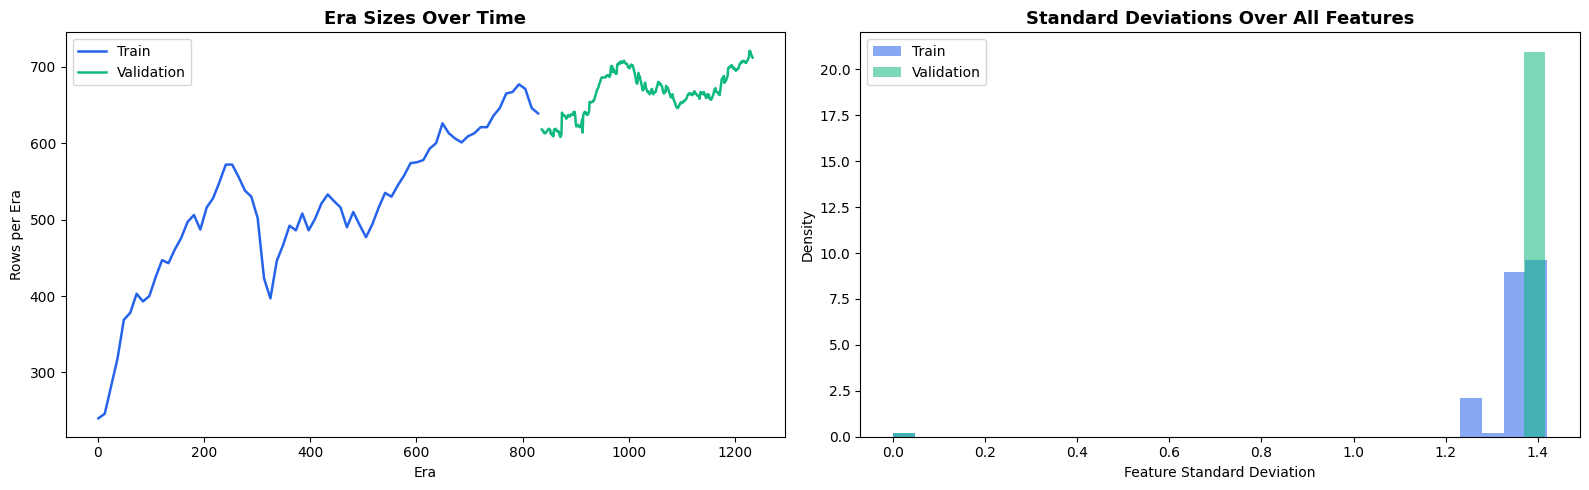

Top 10 Features according to absolute correlation with target:


feature_charisma_148        0.018455
feature_strength_16         0.014350
feature_wisdom_41           0.014144
feature_charisma_11         0.012393
feature_strength_53         0.011553
feature_charisma_5          0.011271
feature_strength_71         0.010718
feature_charisma_2          0.010390
feature_constitution_229    0.010354
feature_constitution_29     0.010084
dtype: float64

ADF Stationarity Check on Top 10 Features (Per-Era Means):


,feature,adf_stat,adf_pvalue,stationary_at_5pct
0,feature_charisma_148,-4.0879,0.0010,True
1,feature_strength_16,-3.2681,0.0164,True
2,feature_wisdom_41,-3.6352,0.0051,True
3,feature_charisma_11,-2.5814,0.0969,False
4,feature_strength_53,-2.4356,0.1319,False
5,feature_charisma_5,-4.1550,0.0008,True
6,feature_strength_71,-3.5303,0.0072,True
7,feature_charisma_2,-3.9553,0.0017,True
8,feature_constitution_229,-4.1317,0.0009,True
9,feature_constitution_29,-3.8042,0.0029,True


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

train_era_sizes = train_df.groupby(ERA_COL)[TARGET_COL].size()
val_era_sizes = validation_df.groupby(ERA_COL)[TARGET_COL].size()
axes[0].plot(train_era_sizes.index, train_era_sizes.to_numpy(), color='#2563eb', linewidth=1.8, label='Train')
axes[0].plot(val_era_sizes.index, val_era_sizes.to_numpy(), color='#10b981', linewidth=1.8, label='Validation')
axes[0].set_title('Era Sizes Over Time', weight='bold', fontsize=13)
axes[0].set_xlabel('Era')
axes[0].set_ylabel('Rows per Era')
axes[0].legend()

train_feat_stds = train_df[feature_columns].astype(np.float32).std()
val_feat_stds = validation_df[feature_columns].astype(np.float32).std()
axes[1].hist(train_feat_stds, bins=30, alpha=0.55, density=True, color='#2563eb', label='Train')
axes[1].hist(val_feat_stds, bins=30, alpha=0.55, density=True, color='#10b981', label='Validation')
axes[1].set_title('Standard Deviations Over All Features', weight='bold', fontsize=13)
axes[1].set_xlabel('Feature Standard Deviation')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()

corr_with_target = train_df[feature_columns].corrwith(train_df[TARGET_COL]).abs().sort_values(ascending=False)
print('Top 10 Features according to absolute correlation with target:')
display(corr_with_target.head(10))

eda_stationarity_df = compute_eda_era_stationarity(train_df, list(corr_with_target.head(10).index), era_col=ERA_COL)
print('ADF Stationarity Check on Top 10 Features (Per-Era Means):')
display(eda_stationarity_df)

In [6]:
input_columns = [ERA_COL] + ([TICKER_COL] if TICKER_COL in train_df.columns and TICKER_COL in validation_df.columns else []) + feature_columns
X_train = train_df[input_columns].reset_index(drop=True)
y_train = train_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
train_eras = train_df[ERA_COL].astype(np.int32).reset_index(drop=True)

X_validation = validation_df[input_columns].reset_index(drop=True)
y_validation = validation_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
validation_eras = validation_df[ERA_COL].astype(np.int32).reset_index(drop=True)

# Retain only lightweight validation metadata for diagnostics export, date-aware staking, and free raw DataFrames
val_diag_meta = validation_df[[c for c in ('id', 'numerai_ticker', 'date', ERA_COL) if c in validation_df.columns]].reset_index(drop=True).copy()
val_era_dates = (
    val_diag_meta.groupby(ERA_COL, sort=True)['date'].first()
    if ('date' in val_diag_meta.columns and ERA_COL in val_diag_meta.columns)
    else None
)
del train_df, validation_df
gc.collect()

# Era-level purged CV splitter supporting 'timeseries', 'purged_kfold' (AFML Ch. 7), and 'cpcv' (AFML Ch. 12)
cv_object = build_era_cv_splits(
    train_eras,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    target_horizon_eras=target_horizon_eras,
    embargo_eras=embargo_eras,
)
print(
    f'Built {len(cv_object)} strictly era-purged CV fold(s) using cv_strategy={cv_strategy!r} '
    f'(horizon={target_horizon_eras} eras, embargo={embargo_eras} eras)'
)


Built 1 strictly era-purged CV fold(s) using cv_strategy='timeseries' (horizon=12 eras, embargo=1 eras)


In [7]:
raw_feature_sets = feature_metadata.get('feature_sets', {})
meta_set_names = {'small', 'medium', 'all'}
active_feature_set_cols = set(feature_columns)
unity_feature_groups_dict = {
    group_name: tuple(col for col in group_cols if col in active_feature_set_cols)
    for group_name, group_cols in raw_feature_sets.items()
    if group_name not in meta_set_names and isinstance(group_cols, list)
}
unity_feature_groups_dict = {k: v for k, v in unity_feature_groups_dict.items() if len(v) >= 2}
unity_feature_groups = tuple(sorted(unity_feature_groups_dict.items())) if unity_feature_groups_dict else None

numerai_extractions = NumeraiExtractions(
    era_col=ERA_COL,
    target_col=TARGET_COL,
    ticker_col=TICKER_COL,
    year_horizon_filter=None,
    variance_threshold=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    top_k=None,
    feature_selection_percentile=None,
    sparse_selector=None,
    sparse_alpha=0.01,
    pca_n_components=None,
    quantize_scope='era',
    quantize_strategy='zscore',
    sequence_top_n=4,
    feature_groups=unity_feature_groups,
    basic_group_stats=None,
    fourier_period_eras=52,
    fourier_order=None,
    rolling_era_windows=(4, 12),
    include_rolling_era=False,
    era_lag_scales=(1, 2, 4),
    include_lag_diff=False,
    ticker_features=None,
    ticker_windows=(4, 12),
    ticker_lag_steps=None,
    era_dispersion_features=None,
    missing_fill_value=2.0,
)

bin_snapping_estimator = BinSnappingEstimator(
    extractor=clone(numerai_extractions),
    top_k=20,
    n_bins=5,
    correlation_method='pandas_mean',
    abs_corr=True,
    smoothing=0.0,
    agg_mode='mean',
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

lag_reversal_estimator = LagReversalEstimator(
    extractor=clone(numerai_extractions),
    lag=1,
    acf_mode='feature_mean',
    acf_metric='acf',
    acf_detrend='linear',
    acf_threshold=0.0,
    sign_mode='hard',
    top_k=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    center_features=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

persistence_estimator = PersistenceEstimator(
    extractor=None,
    ticker_col=TICKER_COL,
    persistence_mode='last',
    persistence_lag=target_horizon_eras,
    smoothing=0.0,
    top_k=None,
    correlation_method=None,
    abs_corr=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

bin_snapping_pipeline = Pipeline([('estimator', bin_snapping_estimator)])
lag_reversal_pipeline = Pipeline([('estimator', lag_reversal_estimator)])
persistence_pipeline = Pipeline([('estimator', persistence_estimator)])
print('Baseline A pipeline ready:', bin_snapping_pipeline)
print('Baseline E pipeline ready:', lag_reversal_pipeline)
print('Persistence pipeline ready:', persistence_pipeline)

Baseline A pipeline ready: Pipeline(steps=[('estimator',
                 BinSnappingEstimator(extractor=NumeraiExtractions(),
                                      target_horizon_eras=12, verbose=3))])
Baseline E pipeline ready: Pipeline(steps=[('estimator',
                 LagReversalEstimator(extractor=NumeraiExtractions(),
                                      target_horizon_eras=12, verbose=3))])
Persistence pipeline ready: Pipeline(steps=[('estimator',
                 PersistenceEstimator(persistence_lag=12,
                                      target_horizon_eras=12, verbose=3))])


# Params

## Grid

In [8]:
# SHARED `NumeraiExtractions` GRID SPACE (Used by both `BinSnappingEstimator` and `LagReversalEstimator`)
GRID_EXTRACTOR_PARAM_SPACE = {
    # ----------------------------------------------------------
    # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
    # ----------------------------------------------------------
    'estimator__extractor__era_col': [ERA_COL],
    'estimator__extractor__ticker_col': [TICKER_COL],
    'estimator__extractor__target_col': [
        TARGET_COL,
        # 'target_cyrusd_20',
        # 'target_teager2b_20',
    ],
    'estimator__extractor__year_horizon_filter': [
        None,
        # (1, 2, 3),
        # (4, 5, 6),
        # (7, 8, 9),
    ],
    'estimator__extractor__variance_threshold': [
        None,
        # 0.02,
        # 0.05,
        # 0.10,
    ],
    'estimator__extractor__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman'
    ],
    'estimator__extractor__abs_corr': [
        True,
        # False,
    ],
    'estimator__extractor__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__extractor__feature_selection_percentile': [
        None,
        # 25.0,
        # 50.0,
        # 75.0,
        # 100.0,
    ],
    'estimator__extractor__sparse_selector': [
        None,
        # 'lasso',
        # 'elasticnet',
    ],
    'estimator__extractor__sparse_alpha': [
        0.01,
        # 0.001,
        # 0.1,
    ],
    'estimator__extractor__pca_n_components': [
        None,
        # 10,
        # 20,
        # 0.90,
    ],
    'estimator__extractor__quantize_scope': [
        'era',
        # 'train_fit',
        # 'global',
    ],
    'estimator__extractor__quantize_strategy': [
        'zscore',
        # 'quantile',
    ],
    'estimator__extractor__sequence_top_n': [
        4,
        # 2,
        # 8,
    ],
    'estimator__extractor__missing_fill_value': [
        2.0,
        # 0.0,
        # 4.0,
        # 'mean',
        # 'median',
        # 'era_mean',
        # 'era_median',
    ],

    # ----------------------------------------------------------
    # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
    # ----------------------------------------------------------
    'estimator__extractor__basic_group_stats': [
        None,
        # 'mean',
        # 'std',
        # 'skew',
        # 'mean|std',
        # 'mean|skew',
        # 'std|skew',
        # 'mean|std|skew',
    ],
    'estimator__extractor__fourier_period_eras': [
        52,
        # 26,
        # 13,
    ],
    'estimator__extractor__fourier_order': [
        None,
        # 1,
        # 2,
        # 3,
    ],
    'estimator__extractor__rolling_era_windows': [
        (4, 12),
        # (2, 6, 12),
        # (4, 8, 16),
    ],
    'estimator__extractor__include_rolling_era': [
        False,
        # True,
    ],
    'estimator__extractor__era_lag_scales': [
        (1, 2, 4),
        # (1, 2, 4, 8),
        # (2, 4, 8),
    ],
    'estimator__extractor__include_lag_diff': [
        False,
        # True,
    ],
    'estimator__extractor__ticker_features': [
        None,
        # 'rolling_mean',
        # 'momentum_diff',
        # 'weeks_since_high',
        # 'rolling_rank',
        # 'weeks_since_change',
        # 'expanding_stats',
        # 'raw_lags',
        # 'rolling_mean|momentum_diff',
        # 'rolling_mean|momentum_diff|rolling_rank',
        # 'expanding_stats|raw_lags',
        # 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
    ],
    'estimator__extractor__ticker_windows': [
        (4, 12),
        # (2, 6, 12),
    ],
    'estimator__extractor__ticker_lag_steps': [
        None,
        # (1, 2),
        # (1, 2, 4),
    ],
    'estimator__extractor__era_dispersion_features': [
        None,
        # 'mean',
        # 'std',
        # 'extreme_frac',
        # 'mean|std',
        # 'mean|extreme_frac',
        # 'std|extreme_frac',
        # 'mean|std|extreme_frac',
    ],
}

GRID_PARAM_SPACE_BIN_SNAPPING = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # MODEL — Baseline A (`BinSnappingEstimator` — Map Matching Lookup Table)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__top_k': [
        20,
        # None,
        # 10,
        # 40,
    ],
    'estimator__n_bins': [
        5,
        # 3,
        # 7,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__smoothing': [
        0.0,
        # 25.0,
        # 50.0,
        # 100.0,
    ],
    'estimator__agg_mode': [
        'mean',
        # 'corr_weighted',
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
        # 'uniqueness',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

GRID_PARAM_SPACE_LAG_REVERSAL = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # MODEL — Baseline E (`LagReversalEstimator` — Era Autocorrelation / PACF Sign & Shrinkage Rule)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__lag': [
        1,
        # 2,
        # 4,
        # 6,
    ],
    'estimator__acf_mode': [
        'feature_mean',
        # 'feature_corr',
    ],
    'estimator__acf_metric': [
        'acf',
        # 'pacf',
    ],
    'estimator__acf_detrend': [
        'linear',
        # None,
        # 'constant',
    ],
    'estimator__acf_threshold': [
        0.0,
        # -0.05,
        # 0.05,
    ],
    'estimator__sign_mode': [
        'hard',
        # 'soft_threshold',
        # 'tanh',
    ],
    'estimator__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__center_features': [
        True,
        # False,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
        # 'uniqueness',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

# Decoupled Persistence Grid Space (Does NOT inherit `GRID_EXTRACTOR_PARAM_SPACE`)
GRID_PARAM_SPACE_PERSISTENCE = {
    # ----------------------------------------------------------
    # MODEL — Baseline P (`PersistenceEstimator` — Brownlee Target Persistence / Zero-Rule)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__ticker_col': [TICKER_COL],
    'estimator__persistence_mode': [
        'last',
        # 'expanding_mean',
        # None,
    ],
    'estimator__persistence_lag': [target_horizon_eras],
    'estimator__smoothing': [
        0.0,
        # 10.0,
        # 25.0,
        # 50.0,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
        # 'uniqueness',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

## Bayesian

In [9]:
# BAYESIAN SEARCH ONLY
# Shared `BAYESIAN_EXTRACTOR_PARAM_SPACE` is used by both `BinSnappingEstimator` and `LagReversalEstimator`.
# Mode/selection parameters start with `None` (off); boolean `include_*` flags use `[False, True]`.
BAYESIAN_EXTRACTOR_PARAM_SPACE = dict()
BAYESIAN_PARAM_SPACE_BIN_SNAPPING = dict()
BAYESIAN_PARAM_SPACE_LAG_REVERSAL = dict()
BAYESIAN_PARAM_SPACE_PERSISTENCE = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_EXTRACTOR_PARAM_SPACE = {
        # ----------------------------------------------------------
        # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
        # ----------------------------------------------------------
        'estimator__extractor__era_col': Categorical([ERA_COL]),
        'estimator__extractor__ticker_col': Categorical([TICKER_COL]),
        'estimator__extractor__target_col': Categorical([
            TARGET_COL,
        ]),
        'estimator__extractor__year_horizon_filter': Categorical([
            None,
            (1, 2, 3),
            (4, 5, 6),
            (7, 8, 9),
        ]),
        'estimator__extractor__variance_threshold': Categorical([
            None,
            0.02,
            0.05,
            0.10,
        ]),
        'estimator__extractor__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__extractor__abs_corr': Categorical([True, False]),
        'estimator__extractor__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__feature_selection_percentile': Categorical([
            None,
            25.0,
            50.0,
            75.0,
            100.0,
        ]),
        'estimator__extractor__sparse_selector': Categorical([
            None,
            'lasso',
            'elasticnet',
        ]),
        'estimator__extractor__sparse_alpha': Real(1e-4, 1e-1, prior='log-uniform'),
        'estimator__extractor__pca_n_components': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__quantize_scope': Categorical([
            'era',
            'train_fit',
            'global',
        ]),
        'estimator__extractor__quantize_strategy': Categorical([
            'zscore',
            'quantile',
        ]),
        'estimator__extractor__sequence_top_n': Categorical([
            2,
            4,
            8,
        ]),
        'estimator__extractor__missing_fill_value': Categorical([
            2.0,
            0.0,
            4.0,
            'mean',
            'median',
            'era_mean',
            'era_median',
        ]),

        # ----------------------------------------------------------
        # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
        # ----------------------------------------------------------
        'estimator__extractor__basic_group_stats': Categorical([
            None,
            'mean',
            'std',
            'skew',
            'mean|std',
            'mean|skew',
            'std|skew',
            'mean|std|skew',
        ]),
        'estimator__extractor__fourier_period_eras': Categorical([
            52,
            26,
            13,
        ]),
        'estimator__extractor__fourier_order': Categorical([
            None,
            1,
            2,
            3,
        ]),
        'estimator__extractor__rolling_era_windows': Categorical([
            (4, 12),
            (2, 6, 12),
            (4, 8, 16),
        ]),
        'estimator__extractor__include_rolling_era': Categorical([False, True]),
        'estimator__extractor__era_lag_scales': Categorical([
            (1, 2, 4),
            (1, 2, 4, 8),
            (2, 4, 8),
        ]),
        'estimator__extractor__include_lag_diff': Categorical([False, True]),
        'estimator__extractor__ticker_features': Categorical([
            None,
            'rolling_mean',
            'momentum_diff',
            'weeks_since_high',
            'rolling_rank',
            'weeks_since_change',
            'expanding_stats',
            'raw_lags',
            'rolling_mean|momentum_diff',
            'rolling_mean|momentum_diff|rolling_rank',
            'expanding_stats|raw_lags',
            'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
        ]),
        'estimator__extractor__ticker_windows': Categorical([
            (4, 12),
            (2, 6, 12),
        ]),
        'estimator__extractor__ticker_lag_steps': Categorical([
            None,
            (1, 2),
            (1, 2, 4),
        ]),
        'estimator__extractor__era_dispersion_features': Categorical([
            None,
            'mean',
            'std',
            'extreme_frac',
            'mean|std',
            'mean|extreme_frac',
            'std|extreme_frac',
            'mean|std|extreme_frac',
        ]),
    }

    BAYESIAN_PARAM_SPACE_BIN_SNAPPING = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # MODEL — Baseline A (`BinSnappingEstimator` — Map Matching Lookup Table)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__n_bins': Categorical([
            5,
            3,
            7,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__smoothing': Real(0.0, 100.0),
        'estimator__agg_mode': Categorical(['mean', 'corr_weighted']),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
            'uniqueness',
            'uniqueness_decay',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_BIN_SNAPPING = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_BIN_SNAPPING, bin_snapping_pipeline),
        total_n_iter=n_iter,
    )

    BAYESIAN_PARAM_SPACE_LAG_REVERSAL = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # MODEL — Baseline E (`LagReversalEstimator` — Era Autocorrelation / PACF Sign & Shrinkage Rule)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__lag': Integer(1, 6),
        'estimator__acf_mode': Categorical(['feature_mean', 'feature_corr']),
        'estimator__acf_metric': Categorical(['acf', 'pacf']),
        'estimator__acf_detrend': Categorical([
            None,
            'linear',
            'constant',
        ]),
        'estimator__acf_threshold': Real(-0.20, 0.20),
        'estimator__sign_mode': Categorical([
            'hard',
            'soft_threshold',
            'tanh',
        ]),
        'estimator__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__center_features': Categorical([True, False]),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
            'uniqueness',
            'uniqueness_decay',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_LAG_REVERSAL = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_LAG_REVERSAL, lag_reversal_pipeline),
        total_n_iter=n_iter,
    )

    # Decoupled Persistence Bayesian Space (Does NOT inherit `BAYESIAN_EXTRACTOR_PARAM_SPACE`)
    BAYESIAN_PARAM_SPACE_PERSISTENCE = {
        # ----------------------------------------------------------
        # MODEL — Baseline P (`PersistenceEstimator` — Brownlee Target Persistence / Zero-Rule)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__ticker_col': Categorical([TICKER_COL]),
        'estimator__persistence_mode': Categorical([
            None,
            'last',
            'expanding_mean',
        ]),
        'estimator__persistence_lag': Categorical([target_horizon_eras]),
        'estimator__smoothing': Real(0.0, 100.0),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
            'uniqueness',
            'uniqueness_decay',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_PERSISTENCE = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_PERSISTENCE, persistence_pipeline),
        total_n_iter=n_iter,
    )

bin_snapping_param_names = set(bin_snapping_pipeline.get_params(deep=True))
lag_reversal_param_names = set(lag_reversal_pipeline.get_params(deep=True))
persistence_param_names = set(persistence_pipeline.get_params(deep=True))
assert set(GRID_PARAM_SPACE_BIN_SNAPPING).issubset(bin_snapping_param_names)
assert set(GRID_PARAM_SPACE_LAG_REVERSAL).issubset(lag_reversal_param_names)
assert set(GRID_PARAM_SPACE_PERSISTENCE).issubset(persistence_param_names)
for _bspace, _pnames in (
    (BAYESIAN_PARAM_SPACE_BIN_SNAPPING, bin_snapping_param_names),
    (BAYESIAN_PARAM_SPACE_LAG_REVERSAL, lag_reversal_param_names),
    (BAYESIAN_PARAM_SPACE_PERSISTENCE, persistence_param_names),
):
    _bkeys = set().union(*(sub.keys() for sub, _ in _bspace)) if isinstance(_bspace, list) else set(_bspace)
    assert _bkeys.issubset(_pnames)

if search_mode == 'bayes':
    bin_snapping_param_space = BAYESIAN_PARAM_SPACE_BIN_SNAPPING
    lag_reversal_param_space = BAYESIAN_PARAM_SPACE_LAG_REVERSAL
    persistence_param_space = BAYESIAN_PARAM_SPACE_PERSISTENCE
else:
    bin_snapping_param_space = GRID_PARAM_SPACE_BIN_SNAPPING
    lag_reversal_param_space = GRID_PARAM_SPACE_LAG_REVERSAL
    persistence_param_space = GRID_PARAM_SPACE_PERSISTENCE
print(f'Active search_mode={search_mode} | baseline_mode={baseline_mode}')

Active search_mode=bayes | baseline_mode=persistence


# Train

In [10]:
_train_t0 = time.perf_counter()
baseline_results = {}
search_summary_rows = []
cv_results_by_baseline = {}
fitted_default_models = {}

error_bin_cfg = {
    'mode': error_bin_mode,
    'pct_bins': error_pct_bins,
    'zero_tols': error_zero_tols,
    'abs_bins': error_abs_bins,
}

persistence_jobs = []
if baseline_mode in ('persistence', 'all'):
    persistence_jobs.append(('Baseline P (Persistence)', persistence_pipeline, persistence_param_space))

heavy_jobs = []
if baseline_mode in ('baseline_a', 'both', 'all'):
    heavy_jobs.append(('Baseline A (Bin-Snapping)', bin_snapping_pipeline, bin_snapping_param_space))
if baseline_mode in ('baseline_e', 'both', 'all'):
    heavy_jobs.append(('Baseline E (Lag-Reversal)', lag_reversal_pipeline, lag_reversal_param_space))

_cpu_count = os.cpu_count() or 1
_job_budget = _cpu_count if int(n_jobs) == -1 else max(1, int(n_jobs))
outer_jobs = min(_job_budget, len(heavy_jobs)) if heavy_jobs else 1

effective_cache_max_entries = (
    min(int(extraction_cache_max_entries), 2)
    if (outer_jobs > 1 and str(feature_set).strip().lower() in ('medium', 'all'))
    else int(extraction_cache_max_entries)
)
extraction_cache_cfg = {
    'enabled': extraction_cache_enabled,
    'max_entries': effective_cache_max_entries,
}

common_run_kwargs = dict(
    search_mode=search_mode,
    score_version=score_version,
    eval_mode=eval_mode,
    cv_object=cv_object,
    n_iter=n_iter,
    random_state=random_state,
    verbose=verbose,
    error_score=error_score,
    n_jobs=1,
    walk_forward_step_eras=walk_forward_step_eras,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=era_stride,
    error_bin_config=error_bin_cfg,
    extraction_cache_config=extraction_cache_cfg,
)

# 1. Run Baseline P (Persistence) first in the main process on metadata-only columns (0 feature copies)
persistence_payloads = []
if persistence_jobs:
    persist_cols = [c for c in (ERA_COL, TICKER_COL) if c in X_train.columns]
    X_train_persist = X_train[persist_cols]
    X_val_persist = X_validation[persist_cols]
    print(f'Running Baseline P (Persistence) in main process on {persist_cols} (0 feature columns copied)')
    for b_name, b_pipe, b_space in persistence_jobs:
        persistence_payloads.append(
            run_baseline(
                b_name, b_pipe, b_space,
                X_train_persist, y_train, train_eras,
                X_val_persist, y_validation, validation_eras,
                [],
                **common_run_kwargs,
            )
        )
    del X_train_persist, X_val_persist

# 2. Run heavy feature baselines (A & E) in parallel via loky with memmap (max_nbytes='10M', at most 2 workers)
heavy_payloads = []
if heavy_jobs:
    print(
        f'Running {len(heavy_jobs)} heavy baseline(s) with outer_jobs={outer_jobs} '
        f'(n_jobs={n_jobs}, cpu_count={_cpu_count}, inner cv_n_jobs=1, extraction_cache_max_entries={effective_cache_max_entries})'
    )
    if outer_jobs > 1:
        heavy_payloads = Parallel(n_jobs=outer_jobs, backend='loky', max_nbytes='10M')(
            delayed(run_baseline)(
                b_name, b_pipe, b_space,
                X_train, y_train, train_eras,
                X_validation, y_validation, validation_eras,
                feature_columns,
                **common_run_kwargs,
            )
            for b_name, b_pipe, b_space in heavy_jobs
        )
    else:
        heavy_payloads = [
            run_baseline(
                b_name, b_pipe, b_space,
                X_train, y_train, train_eras,
                X_validation, y_validation, validation_eras,
                feature_columns,
                **common_run_kwargs,
            )
            for b_name, b_pipe, b_space in heavy_jobs
        ]

# Merge in original A -> E -> P order
payloads = list(heavy_payloads) + list(persistence_payloads)
for b_name, b_results, b_cv_df, b_summary_row, b_default_model in payloads:
    baseline_results.update(b_results)
    cv_results_by_baseline[b_name] = b_cv_df
    search_summary_rows.append(b_summary_row)
    fitted_default_models[b_name] = b_default_model

train_elapsed_s = time.perf_counter() - _train_t0
print(f'Completed {len(payloads)} baseline(s) in {train_elapsed_s:.1f}s (heavy outer_jobs={outer_jobs})')

Running Baseline P (Persistence) in main process on ['era', 'numerai_ticker'] (0 feature columns copied)
  [AFML Purge | Baseline P (Persistence)] Purged 1 trailing train era(s) (cutoff <= era 824, min_val_era=836, horizon=12) before static validation fits.
--- Baseline P (Persistence) — Final Training Scores ---
Percentage Summary | Numerai CORR: +0.29% | Positive Eras: 52.2% | Era Consistency (>0.002): 50.7% | Directional Accuracy: 34.6%
Numerai CORR: 0.0029
Spearman Correlation: 0.0016
Average Payout (Legacy Spearman Proxy): 0.0081
Sharpe Ratio (Numerai / Lo-Adj / Spearman): 0.0557 / 0.0572 / 0.0319 | PSR (SR > 0): 0.6782 | MinTRL: 860.1 eras
Cumulative CORR Drawdown: 0.2614 pts | Max TuW: 55 eras (1.06 yr) | HHI (+ / -): 0.0235 / 0.0177
Mean Absolute Error (MAE): 0.2061
Forecast Bias (mean(y - y_hat)): 0.0003
Directional Hit Rate: 0.3464 (34.6%)
Era CORR White-Noise & Regime Tests | Lag-1 ACF: -0.0245 | Ljung-Box p: 0.4024 | ARCH-LM p: 1.0000 | ADF p: 0.0070
Era CORR Tail Risk | Sk

In [11]:
comparison_columns = [
    'variant',
    'score_version',
    'train_corr',
    'validation_corr',
    'validation_spearman',
    'validation_payout',
    'era_consistency_pct',
    'validation_sharpe',
    'validation_lo_sharpe',
    'validation_psr',
    'validation_dsr',
    'effective_n_trials_onc',
    'validation_fnc',
    'validation_fnc_sharpe',
    'tuw_max_eras',
    'hhi_pos',
    'hhi_neg',
    'validation_spearman_sharpe',
    'validation_mae',
    'forecast_bias',
    'directional_hit_rate',
    'era_corr_lag1_acf',
    'ljung_box_pvalue',
    'arch_lm_pvalue',
    'adf_pvalue',
    'era_corr_skew',
    'era_corr_kurtosis',
    'jarque_bera_pvalue',
    'feature_exposure',
    'corr_drawdown',
    'start_capital',
    'end_capital',
    'total_profit',
    'total_return_pct',
    'money_drawdown_pct',
    'max_drawdown_gbp',
    'worst_round_gbp',
    'corr_gap',
    'sanity_status',
]
comparison_df = (
    pd.DataFrame([{column: result.get(column, np.nan) for column in comparison_columns} for result in baseline_results.values()])
    .sort_values(['validation_sharpe', 'validation_corr'], ascending=False, kind='stable')
    .reset_index(drop=True)
)
search_summary_df = (
    pd.DataFrame(search_summary_rows)
    .sort_values('best_cv_score', ascending=False, kind='stable')
    .reset_index(drop=True)
)

# Select the locked winner strictly from Train CV (never pick on held-out validation!)
cv_winner_baseline = str(search_summary_df.loc[0, 'baseline'])
preferred_locked_variants = [
    f'{cv_winner_baseline} [Tuned]',
    f'{cv_winner_baseline} [Tuned Walk-Forward]',
    f'{cv_winner_baseline} [Default]',
]
best_variant_name = next(
    (v for v in preferred_locked_variants if v in baseline_results),
    str(comparison_df.loc[0, 'variant']),
)
best_validation_era_corrs = baseline_results[best_variant_name]['validation_era_corrs']
best_validation_corr = baseline_results[best_variant_name]['validation_corr']

print('Held-Out Validation Comparison (One-Wallet Staking + Split CORR vs Money Drawdowns):')
display(comparison_df)
print(f'Train CV Search Summary ({search_mode}, score_version={score_version}, refit=False):')
display(search_summary_df)
print(f'Train-CV-Locked Winner (evaluated once on held-out validation): {best_variant_name}')

Held-Out Validation Comparison (One-Wallet Staking + Split CORR vs Money Drawdowns):


,variant,score_version,train_corr,validation_corr,validation_spearman,validation_payout,era_consistency_pct,validation_sharpe,validation_lo_sharpe,validation_psr,...,corr_drawdown,start_capital,end_capital,total_profit,total_return_pct,money_drawdown_pct,max_drawdown_gbp,worst_round_gbp,corr_gap,sanity_status
0,Baseline P (Persistence) [Tuned],v1_skepta,-0.0023,0.0068,0.0071,0.0357,53.77,0.1518,0.1287,0.9987,...,0.6337,1000.0,1132.73,132.73,13.27,-2.95,-33.16,-6.48,-0.0091,OK
1,Baseline P (Persistence) [Tuned Walk-Forward],v1_skepta,-0.0023,0.0051,0.0062,0.0312,51.26,0.1181,0.0985,0.9906,...,0.7247,1000.0,1097.63,97.63,9.76,-3.36,-37.60,-5.65,-0.0074,OK
2,Baseline P (Persistence) [Default],v1_skepta,0.0029,0.0035,0.0010,0.0050,50.50,0.0762,0.0595,0.9358,...,0.8043,1000.0,1065.22,65.22,6.52,-3.71,-40.55,-5.79,-0.0006,LOW_SIGNAL_WARNING
3,Baseline P (Persistence) [Walk-Forward],v1_skepta,0.0029,-0.0010,-0.0010,-0.0048,47.24,-0.0223,-0.0183,0.3281,...,1.6395,1000.0,978.94,-21.06,-2.11,-7.54,-78.03,-8.02,0.0039,LOW_SIGNAL_WARNING


Train CV Search Summary (bayes, score_version=v1_skepta, refit=False):


,baseline,search_mode,score_version,best_cv_score,best_cv_corr,best_cv_score_pct,best_params,pbo_cscv
0,Baseline P (Persistence),bayes,v1_skepta,-0.019215,-0.0007,-1.92,"{'estimator__bias_correction': None, 'estimato...",0.8214


Train-CV-Locked Winner (evaluated once on held-out validation): Baseline P (Persistence) [Tuned]


# Analysis

## General

Exported Numerai Diagnostics predictions Parquet (MMC & FNC): /kaggle/working/results_numerai_v6.0_all_eras_stride12_baselines_ae_target_bayes/validation_predictions.parquet


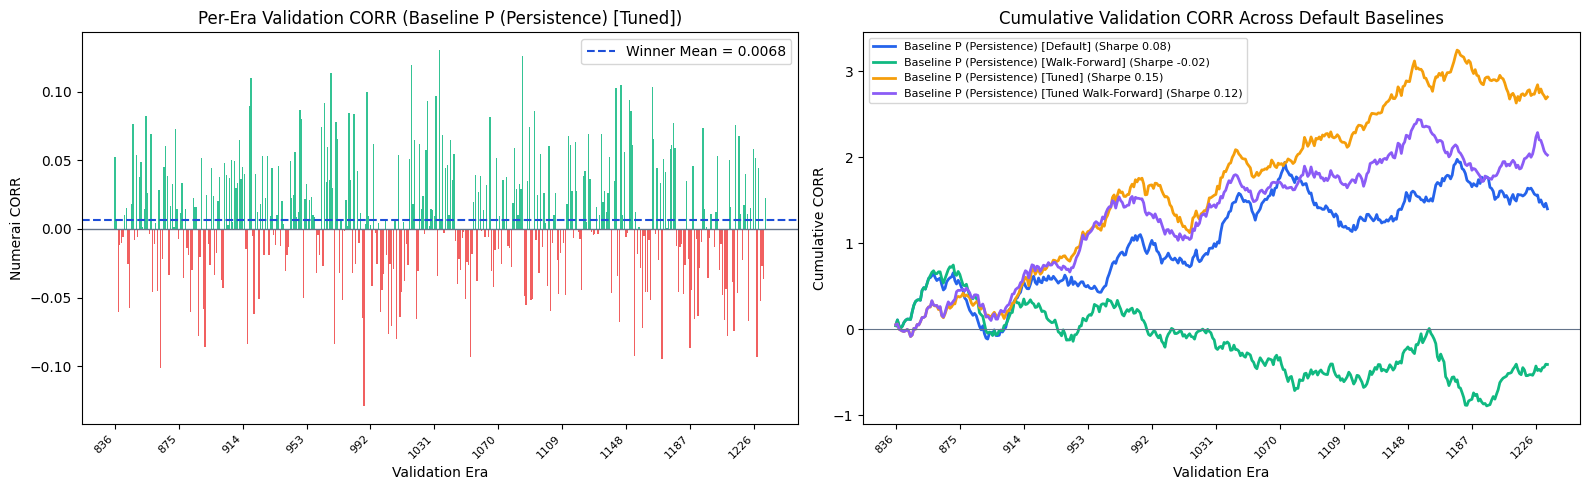

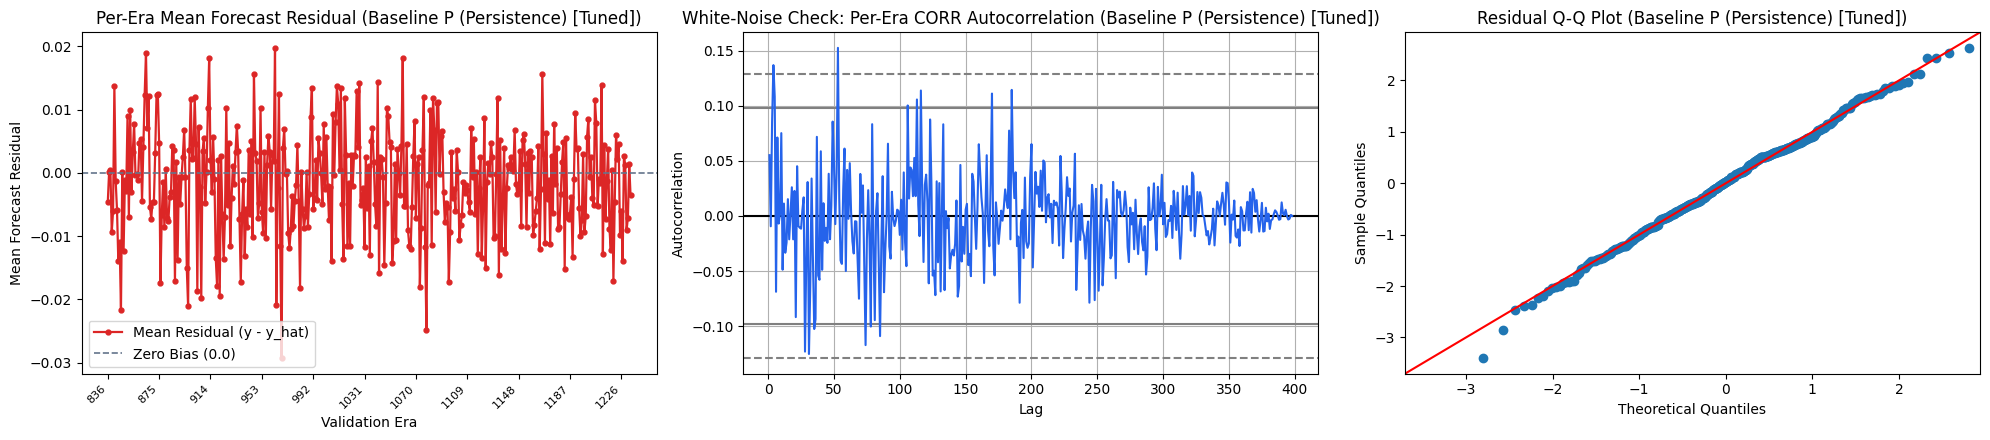

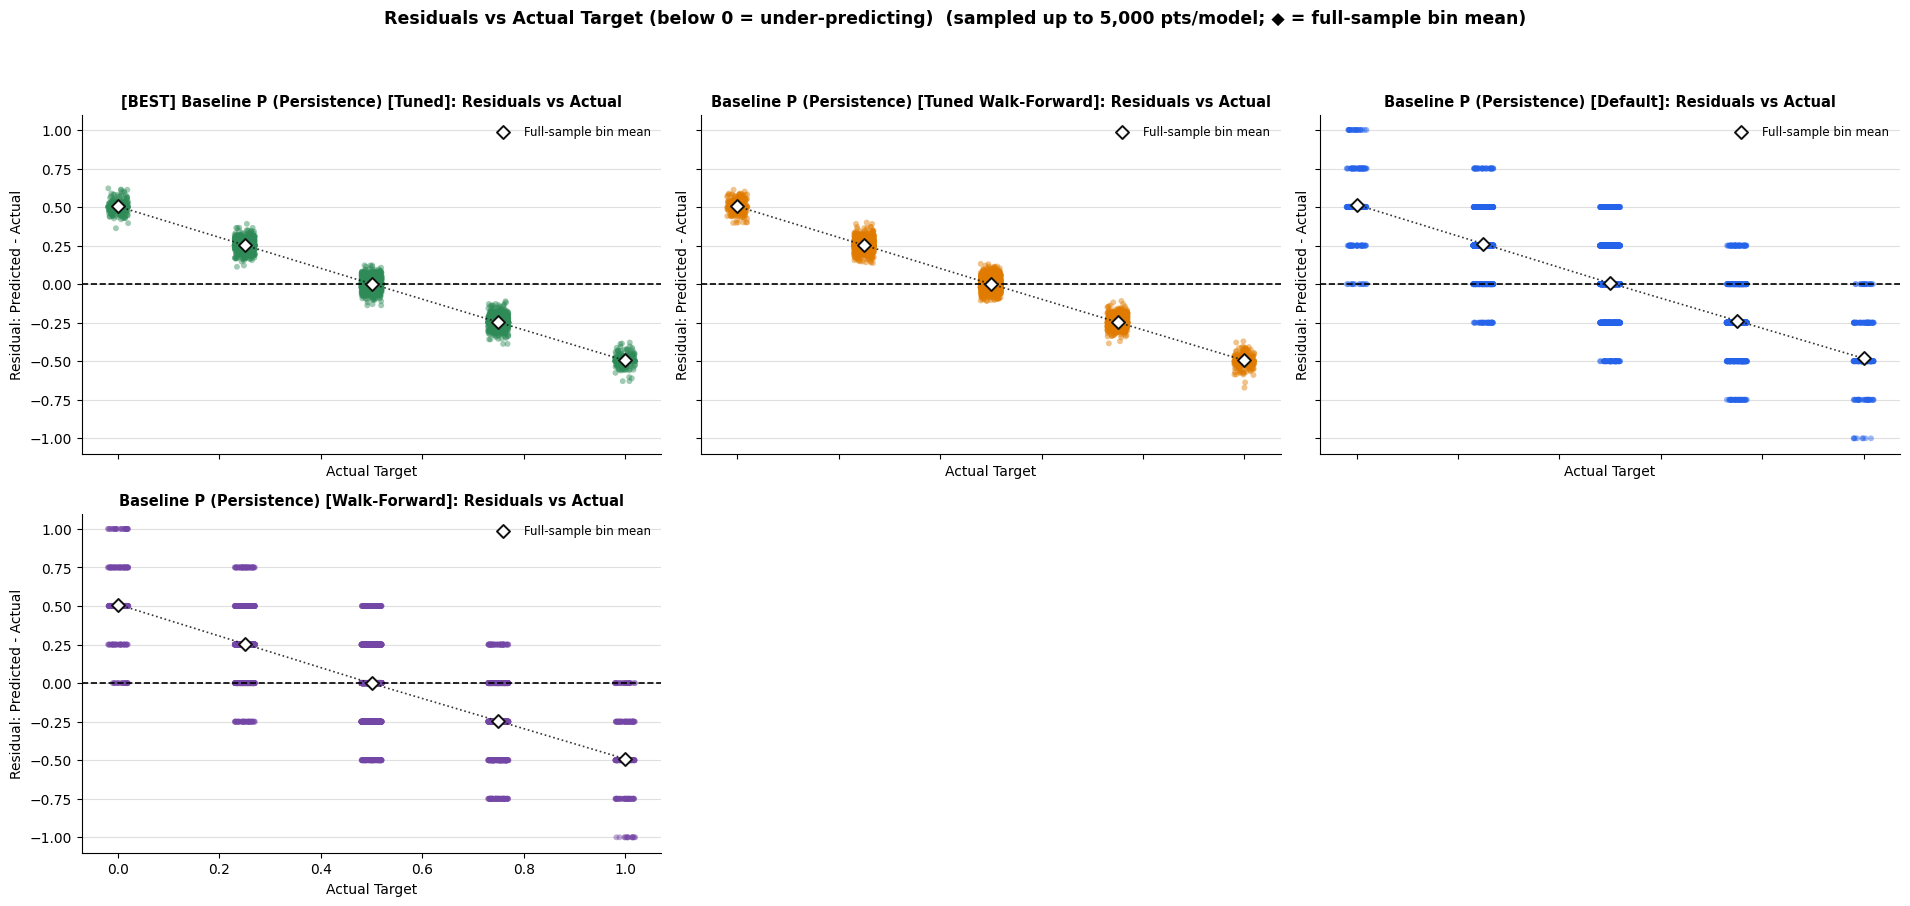

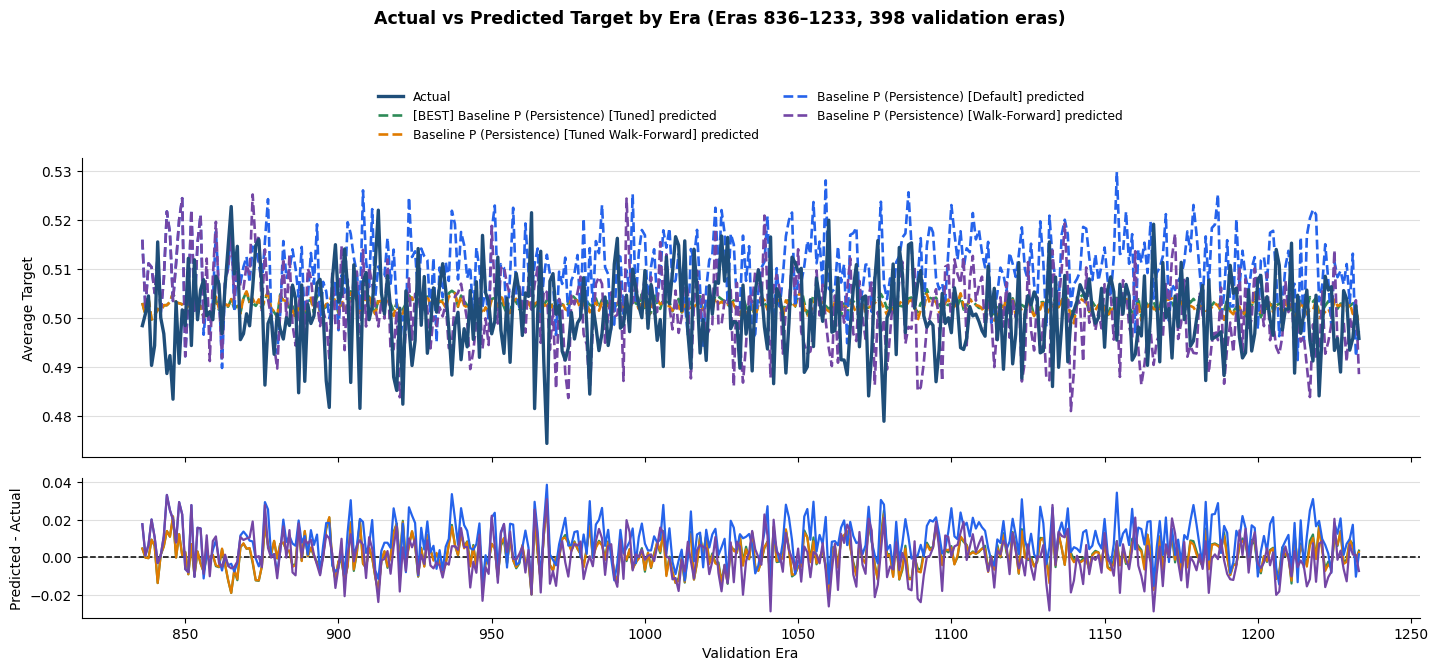

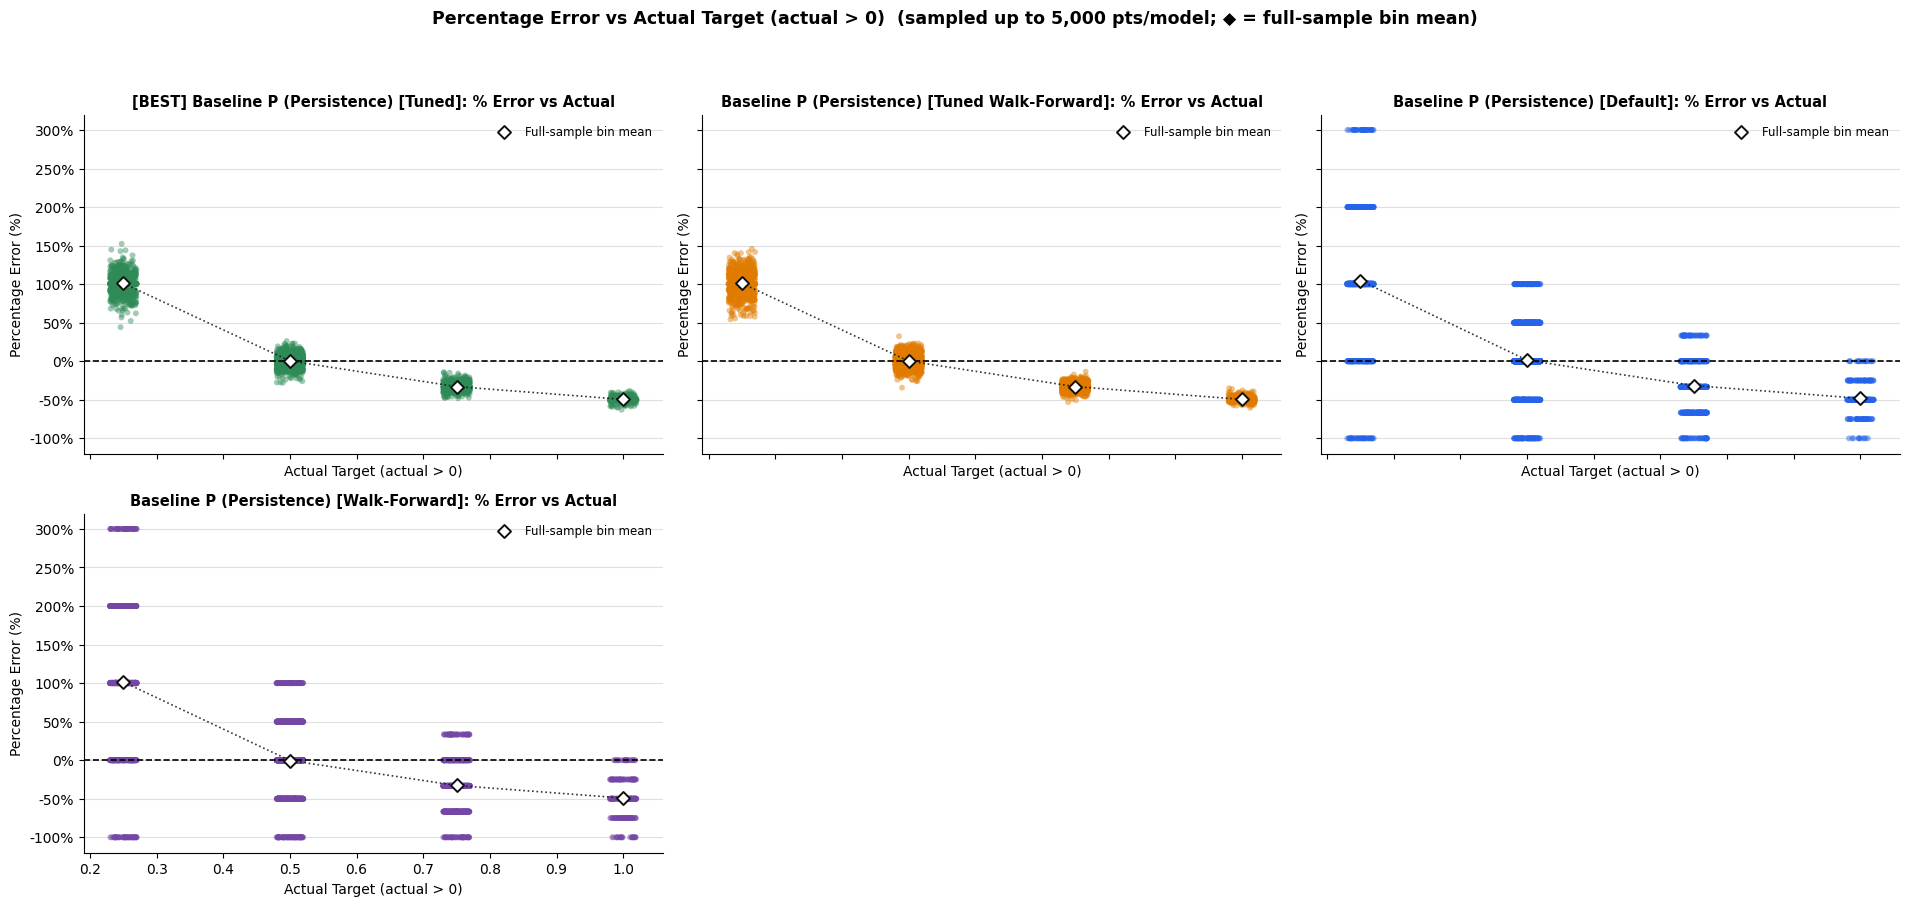

,variant,n_valid,mean_residual,mae,rmse,mean_pct_error_nonzero,under_predict_pct,over_predict_pct
0,[BEST] Baseline P (Persistence) [Tuned],265366,0.001658,0.1584,0.2260,11.60,35.44,64.56
1,Baseline P (Persistence) [Tuned Walk-Forward],265366,0.001402,0.1603,0.2265,11.54,38.46,61.54
2,Baseline P (Persistence) [Default],265366,0.008873,0.2044,0.2934,13.15,28.50,47.36
3,Baseline P (Persistence) [Walk-Forward],265366,0.000503,0.2137,0.3054,11.31,30.01,39.01


In [12]:
era_positions = np.arange(len(best_validation_era_corrs))
tick_step = max(1, len(best_validation_era_corrs) // 10)
tick_labels = best_validation_era_corrs.index.astype(str)[::tick_step]
line_colors = ['#2563eb', '#10b981', '#f59e0b', '#8b5cf6']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.bar(
    era_positions,
    best_validation_era_corrs.to_numpy(),
    color=['#10b981' if era_corr >= 0 else '#ef4444' for era_corr in best_validation_era_corrs.to_numpy()],
    alpha=0.85,
)
ax.axhline(0.0, color='#64748b', linewidth=1.0)
ax.axhline(best_validation_corr, color='#1d4ed8', linestyle='--', linewidth=1.5, label=f'Winner Mean = {best_validation_corr:.4f}')
ax.set_xticks(era_positions[::tick_step])
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Validation Era')
ax.set_ylabel('Numerai CORR')
ax.set_title(f'Per-Era Validation CORR ({best_variant_name})')
ax.legend()

ax = axes[1]
for color_index, (variant_name, result) in enumerate(baseline_results.items()):
    line_color = line_colors[color_index % len(line_colors)]
    ax.plot(
        era_positions,
        result['validation_era_corrs'].cumsum().to_numpy(),
        color=line_color,
        linewidth=2.0,
        label=f"{variant_name} (Sharpe {result['validation_sharpe']:.2f})",
    )
ax.axhline(0.0, color='#64748b', linewidth=0.8)
ax.set_xticks(era_positions[::tick_step])
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Validation Era')
ax.set_ylabel('Cumulative CORR')
ax.set_title('Cumulative Validation CORR Across Default Baselines')
ax.legend(fontsize=8)

plt.tight_layout()
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(results_dir / f'{timestamp}_{experiment_name}_era_perf.png', dpi=140)
    comparison_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_comparison.csv', index=False)
if export_diagnostics or save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    diagnostics_parquet_path = export_diagnostics_predictions(
        val_diag_meta,
        baseline_results[best_variant_name]['validation_preds'],
        results_dir / 'validation_predictions.parquet',
        era_col=ERA_COL,
    )
    print('Exported Numerai Diagnostics predictions Parquet (MMC & FNC):', diagnostics_parquet_path)
plt.show()

# Brownlee Residual, White-Noise & Tail-Normality Diagnostics (Per-Era Mean Residual + Era CORR Autocorrelation + Residual Q-Q Plot)
winner_val_preds = np.asarray(baseline_results[best_variant_name]['validation_preds'], dtype=np.float64).ravel()
winner_residuals = pd.Series(y_validation.to_numpy(dtype=np.float64) - winner_val_preds, index=validation_eras.index)
per_era_mean_residuals = winner_residuals.groupby(validation_eras, sort=True).mean()

fig_res, axes_res = plt.subplots(1, 3, figsize=(20, 4.5))
axes_res[0].plot(era_positions, per_era_mean_residuals.to_numpy(), color='#dc2626', marker='o', markersize=3.5, linewidth=1.6, label='Mean Residual (y - y_hat)')
axes_res[0].axhline(0.0, color='#64748b', linestyle='--', linewidth=1.2, label='Zero Bias (0.0)')
axes_res[0].set_xticks(era_positions[::tick_step])
axes_res[0].set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
axes_res[0].set_xlabel('Validation Era')
axes_res[0].set_ylabel('Mean Forecast Residual')
axes_res[0].set_title(f'Per-Era Mean Forecast Residual ({best_variant_name})')
axes_res[0].legend()

if len(best_validation_era_corrs) >= 2:
    autocorrelation_plot(best_validation_era_corrs, ax=axes_res[1], color='#2563eb')
axes_res[1].set_title(f'White-Noise Check: Per-Era CORR Autocorrelation ({best_variant_name})')

if len(per_era_mean_residuals) >= 3:
    qqplot(per_era_mean_residuals.to_numpy(dtype=np.float64), line='45', fit=True, ax=axes_res[2])
axes_res[2].set_title(f'Residual Q-Q Plot ({best_variant_name})')
plt.tight_layout()
if save_results:
    plt.savefig(results_dir / f'{timestamp}_{experiment_name}_residual_white_noise.png', dpi=140)
plt.show()

# Flight-Notebook Residual Diagnostics (Residuals vs Actual, Actual vs Predicted by Era + Residual, % Error vs Actual)
flight_res_models = {}
seen_res_families = set()
ordered_res_candidates = [best_variant_name] + [
    variant_name for variant_name in comparison_df['variant'].tolist() if variant_name != best_variant_name
]
for variant_name in ordered_res_candidates:
    if variant_name not in baseline_results:
        continue
    model_family = variant_name.split(' [')[0]
    if model_family not in seen_res_families:
        seen_res_families.add(model_family)
        flight_res_models[variant_name] = baseline_results[variant_name]['validation_preds']
if len(flight_res_models) == 1:
    for variant_name in ordered_res_candidates:
        if variant_name in baseline_results and variant_name not in flight_res_models and len(flight_res_models) < 4:
            flight_res_models[variant_name] = baseline_results[variant_name]['validation_preds']

flight_res_save_prefix = (
    results_dir / f'{timestamp}_{experiment_name}_flight_residuals'
    if save_results
    else None
)
flight_residual_summary_df = plot_flight_residual_diagnostics(
    y_validation,
    flight_res_models,
    validation_eras,
    best_variant_name=best_variant_name,
    max_models=4,
    random_state=random_state,
    save_prefix=flight_res_save_prefix,
)
display(flight_residual_summary_df)

In [13]:
if 'Baseline A (Bin-Snapping)' in fitted_default_models:
    fitted_bin_snapping = fitted_default_models['Baseline A (Bin-Snapping)'].named_steps['estimator']
    lookup_table_df = pd.DataFrame(fitted_bin_snapping.lookup_table_).T
    lookup_table_df.columns = [f'bin_{bin_index}' for bin_index in lookup_table_df.columns]
    lookup_table_df['train_corr'] = fitted_bin_snapping.selected_corrs_
    print(f'Baseline A Learned Lookup Table (top {len(lookup_table_df)} features):')
    display(lookup_table_df.head(15))

if 'Baseline E (Lag-Reversal)' in fitted_default_models:
    fitted_lag_reversal = fitted_default_models['Baseline E (Lag-Reversal)'].named_steps['estimator']
    n_kept_signals = int((fitted_lag_reversal.inversion_signs_ > 0).sum())
    n_inverted_signals = int((fitted_lag_reversal.inversion_signs_ < 0).sum())
    print(f'Baseline E Signal Rules | kept (+1)={n_kept_signals} | inverted (-1)={n_inverted_signals}')
    display(fitted_lag_reversal.rule_summary_.head(20))

if 'Baseline P (Persistence)' in fitted_default_models:
    fitted_persistence = fitted_default_models['Baseline P (Persistence)'].named_steps['estimator']
    print(
        f'Baseline P (Persistence) | mode={fitted_persistence.persistence_mode} | '
        f'lag={fitted_persistence.persistence_lag} | global_mean={fitted_persistence.global_mean_:.4f} | '
        f'tracked_tickers={len(fitted_persistence.ticker_lookup_)}'
    )
    display(fitted_persistence.persistence_table_.head(15))

if plt is not None:
    if 'Baseline E (Lag-Reversal)' in fitted_default_models:
        top_rule_df = fitted_lag_reversal.rule_summary_.head(20).copy()
        top_rule_df['abs_weight'] = top_rule_df['effective_weight'].abs()
        plot_rule_df = top_rule_df.sort_values('abs_weight', ascending=True)
        fig_imp, ax_imp = plt.subplots(figsize=(10, 6))
        bar_colors = ['#10b981' if w >= 0 else '#ef4444' for w in plot_rule_df['effective_weight']]
        ax_imp.barh(plot_rule_df['feature'], plot_rule_df['effective_weight'], color=bar_colors, alpha=0.85)
        ax_imp.axvline(0.0, color='#64748b', linewidth=0.9)
        ax_imp.set_xlabel('Effective Signed Weight')
        ax_imp.set_title('Top 20 Baseline E Features by Effective Weight')
        plt.tight_layout()
        if save_results:
            results_dir.mkdir(parents=True, exist_ok=True)
            plt.savefig(results_dir / f'{timestamp}_{experiment_name}_baseline_e_weights.png', dpi=140)
        plt.show()
    elif 'Baseline A (Bin-Snapping)' in fitted_default_models:
        top_bin_df = lookup_table_df.head(20).copy()
        top_bin_df['abs_corr'] = top_bin_df['train_corr'].abs()
        plot_bin_df = top_bin_df.sort_values('abs_corr', ascending=True)
        fig_imp, ax_imp = plt.subplots(figsize=(10, 6))
        bar_colors = ['#2563eb' if c >= 0 else '#ef4444' for c in plot_bin_df['train_corr']]
        ax_imp.barh(plot_bin_df.index, plot_bin_df['train_corr'], color=bar_colors, alpha=0.85)
        ax_imp.axvline(0.0, color='#64748b', linewidth=0.9)
        ax_imp.set_xlabel('Training Target Correlation')
        ax_imp.set_title('Top 20 Baseline A Features by Training Correlation')
        plt.tight_layout()
        if save_results:
            results_dir.mkdir(parents=True, exist_ok=True)
            plt.savefig(results_dir / f'{timestamp}_{experiment_name}_baseline_a_corrs.png', dpi=140)
        plt.show()

Baseline P (Persistence) | mode=expanding_mean | lag=12 | global_mean=0.5013 | tracked_tickers=9761


,ticker,persisted_target,obs_count,last_era
0,HMB SE,0.490184,17,781
1,CARLB DK,0.489310,15,769
2,GLW US,0.533812,15,817
3,MKC US,0.533812,15,781
4,PEP US,0.455933,15,805
5,4904 TW,0.512099,14,709
6,522 HK,0.500456,14,745
7,6412 JP,0.488812,14,793
8,7581 JP,0.453881,14,817
9,8379 JP,0.512099,14,769


In [14]:
for baseline_name, cv_results_df in cv_results_by_baseline.items():
    print(f'Top CV candidates for {baseline_name}:')
    display(cv_results_df.head(10))
    if save_results:
        results_dir.mkdir(parents=True, exist_ok=True)
        baseline_slug = 'baseline_a' if 'Baseline A' in baseline_name else ('baseline_e' if 'Baseline E' in baseline_name else 'persistence')
        cv_results_path = results_dir / f'{timestamp}_{experiment_name}_{baseline_slug}_{search_mode}_cv.csv'
        cv_results_df.to_csv(cv_results_path, index=False)
        print('Saved CV results CSV:', cv_results_path)

Top CV candidates for Baseline P (Persistence):


,candidate_id,rank_test_score,mean_test_score,score_version,end_capital,total_profit,total_return_pct,money_drawdown_pct,mean_directional_accuracy_pct,mean_accurate_pct,...,max_drawdown_gbp,worst_round_gbp,bias_correction,era_weighting,persistence_mode,prediction_transform,recency_decay,smoothing,walk_forward_step_eras,walk_forward_window
0,6,1,-0.019215,v1_skepta,999.55,-0.45,-0.04,-0.57,52.27,35.79,...,-5.72,-3.05,None,None,expanding_mean,None,0.015473,7.471022,40.0,sliding
1,20,2,-0.019508,v1_skepta,999.41,-0.59,-0.06,-0.58,49.63,7.04,...,-5.85,-2.98,mean_residual,None,expanding_mean,era_zscore,0.012892,0.900121,40.0,sliding
2,8,3,-0.019601,v1_skepta,999.11,-0.89,-0.09,-0.57,49.68,33.02,...,-5.66,-3.42,mean_residual,uniqueness_decay,expanding_mean,None,0.011472,6.151725,20.0,expanding
3,21,4,-0.020384,v1_skepta,999.45,-0.55,-0.06,-0.66,51.41,2.78,...,-6.64,-3.62,None,uniqueness,expanding_mean,era_rank,0.017932,3.795053,40.0,sliding
4,15,5,-0.020622,v1_skepta,999.42,-0.58,-0.06,-0.67,50.17,5.84,...,-6.71,-3.60,mean_residual,uniqueness,expanding_mean,era_zscore,0.018396,5.841173,40.0,sliding
5,18,6,-0.021009,v1_skepta,999.11,-0.89,-0.09,-0.68,52.14,37.76,...,-6.77,-3.56,None,equal_era,expanding_mean,None,0.006003,7.773011,NaN,sliding
6,14,7,-0.021109,v1_skepta,998.47,-1.53,-0.15,-0.63,51.79,29.36,...,-6.25,-3.30,None,uniqueness_decay,expanding_mean,None,0.007204,0.303227,20.0,sliding
7,16,8,-0.021159,v1_skepta,999.50,-0.50,-0.05,-0.73,52.14,46.96,...,-7.31,-3.66,mean_residual,equal_era,expanding_mean,None,0.016874,26.829331,40.0,sliding
8,28,9,-0.021162,v1_skepta,997.83,-2.17,-0.22,-0.46,50.30,2.67,...,-4.64,-3.05,mean_residual,recency_exp,expanding_mean,era_rank,0.001604,20.319148,20.0,sliding
9,2,10,-0.021350,v1_skepta,999.01,-0.99,-0.10,-0.69,51.41,2.80,...,-6.88,-3.58,mean_residual,equal_era,expanding_mean,era_rank,0.010938,9.545504,40.0,sliding


Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride12_baselines_ae_target_bayes/20261125_033114_numerai_v6.0_all_eras_stride12_baselines_ae_persistence_bayes_cv.csv


## Error-Direction Envelope Analysis (Per Baseline Model — Best Highlighted)

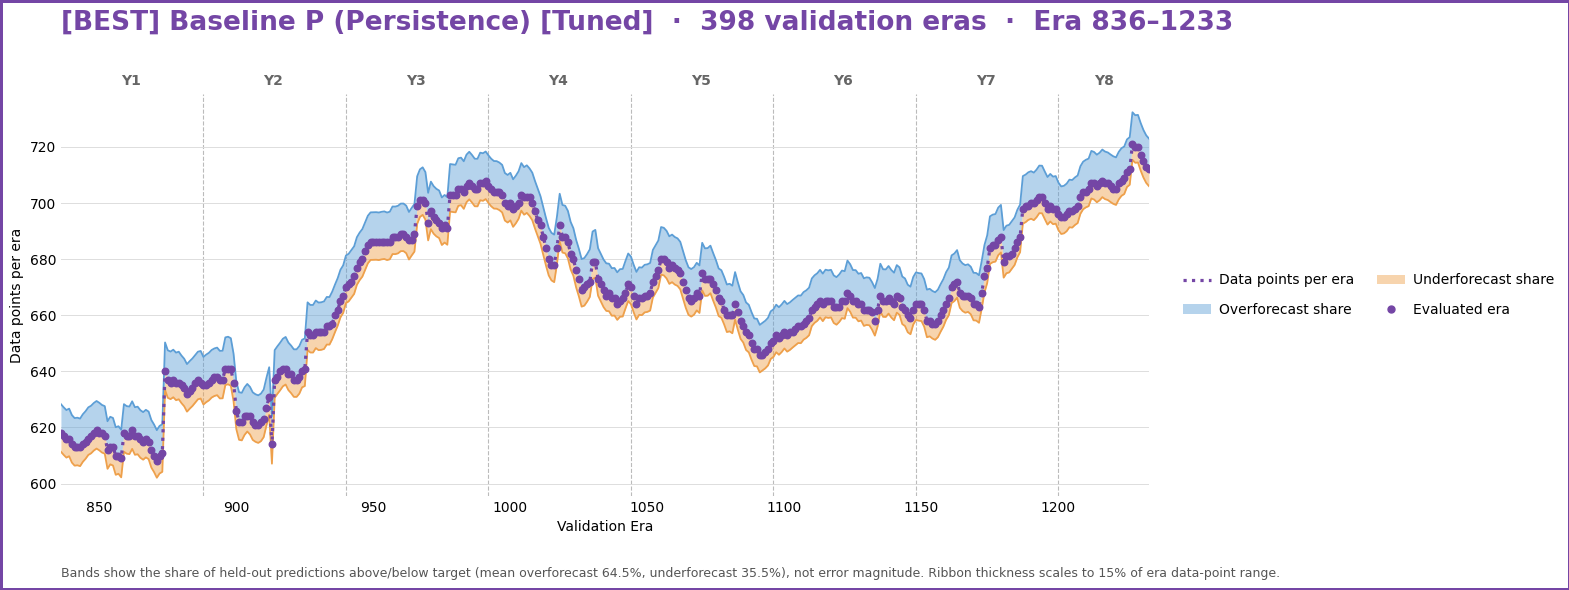

Best Model Envelope Summary (Baseline P (Persistence) [Tuned]):


,data_points,under_share,over_share,mae,mean_residual,is_interpolated
era,,,,,,
836,618,0.391586,0.608414,0.159017,0.004644,False
837,617,0.398703,0.601297,0.155970,-0.000164,False
838,616,0.397727,0.602273,0.168961,-0.000478,False
839,616,0.368506,0.631494,0.154824,0.009369,False
840,614,0.384365,0.615635,0.156152,0.006100,False
841,613,0.389886,0.610114,0.158980,-0.013696,False
842,613,0.381729,0.618271,0.166281,0.001354,False
843,613,0.399674,0.600326,0.168144,0.005822,False
844,614,0.368078,0.631922,0.153477,0.013971,False


In [15]:
envelope_dfs = {}
seen_model_families = set()
envelope_variants = []
ordered_envelope_candidates = [best_variant_name] + [
    variant_name for variant_name in comparison_df['variant'].tolist() if variant_name != best_variant_name
]
for variant_name in ordered_envelope_candidates:
    if variant_name not in baseline_results:
        continue
    model_family = variant_name.split(' [')[0]
    if model_family not in seen_model_families:
        seen_model_families.add(model_family)
        envelope_variants.append(variant_name)

for variant_name in envelope_variants:
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    envelope_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_error_envelope.png'
        if save_results
        else None
    )
    envelope_dfs[variant_name] = plot_era_error_envelope(
        y_validation,
        baseline_results[variant_name]['validation_preds'],
        validation_eras,
        title=variant_name,
        band_size=0.15,
        is_best=is_best_variant,
        save_path=envelope_save_path,
    )

envelope_df = envelope_dfs[best_variant_name]
print(f'Best Model Envelope Summary ({best_variant_name}):')
display(envelope_df.head(10))

## AFML Backtest Overfitting, Risk & Numerai Forum #1454 Diagnostics
Summarizes **Era Consistency (`CORR > 0.002`)**, **Lo (2002) autocorrelation-adjusted Sharpe**, **PSR**, **ONC-Clustered $E[K]$ DSR & Šidák FWER $\alpha_K$**, **MinTRL**, **CSCV Probability of Backtest Overfitting (PBO)**, **Feature Neutral Correlation (FNC)**, **Time under Water (TuW)**, **Return Concentration (HHI)**, and **AFML Ch. 15 Strategy Failure Probability**.

In [16]:
afml_diag_rows = []
for variant_name, res_entry in baseline_results.items():
    base_key = variant_name.split(' [')[0]
    cv_df_ref = cv_results_by_baseline.get(base_key)
    v_trials_mat = cv_df_ref.attrs.get('trials_era_corrs_df') if cv_df_ref is not None else None
    v_trial_srs = (
        cv_df_ref['mean_sharpe'].dropna().to_numpy(dtype=np.float64)
        if (cv_df_ref is not None and 'mean_sharpe' in cv_df_ref.columns and len(cv_df_ref) > 0 and '[Tuned' in variant_name)
        else [res_entry['validation_sharpe']]
    )
    afml_diag_rows.append(
        summarize_afml_backtest_diagnostics(
            res_entry['validation_era_corrs'],
            trial_srs=v_trial_srs,
            trials_matrix=v_trials_mat if '[Tuned' in variant_name else None,
            y_true=y_validation,
            y_pred=res_entry['validation_preds'],
            features_df=X_validation,
            feature_columns=feature_columns,
            eras=validation_eras,
            label=variant_name,
            random_state=random_state,
        )
    )
afml_diagnostics_df = pd.DataFrame(afml_diag_rows)
print('AFML Backtest Risk, Multiple-Testing (ONC-Clustered DSR / PBO) & Numerai Forum #1454 Diagnostics:')
display(afml_diagnostics_df)
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    afml_diagnostics_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_afml_diagnostics.csv', index=False)


AFML Backtest Risk, Multiple-Testing (ONC-Clustered DSR / PBO) & Numerai Forum #1454 Diagnostics:


,variant,n_eras,mean_corr,positive_era_pct,era_consistency_pct,numerai_sharpe,lo_adjusted_sharpe,psr,dsr,effective_n_trials_onc,...,pbo_cscv,fnc_mean,fnc_sharpe,corr_drawdown,tuw_max_eras,tuw_max_years,hhi_pos,hhi_neg,hhi_time,strategy_fail_prob
0,Baseline P (Persistence) [Default],398,0.0035,51.26,50.50,0.0762,0.0595,0.9358,0.9358,1.0,...,NaN,0.0011,0.0244,0.8043,104,2.00,0.0024,0.0026,0.0010,0.8178
1,Baseline P (Persistence) [Walk-Forward],398,-0.0010,48.99,47.24,-0.0223,-0.0183,0.3281,0.3281,1.0,...,NaN,-0.0024,-0.0547,1.6395,362,6.96,0.0026,0.0028,0.0017,0.9995
2,Baseline P (Persistence) [Tuned],398,0.0068,55.03,53.77,0.1518,0.1287,0.9987,0.5954,6.0,...,0.8214,0.0042,0.0992,0.6337,55,1.06,0.0024,0.0035,0.0016,0.1530
3,Baseline P (Persistence) [Tuned Walk-Forward],398,0.0051,54.02,51.26,0.1181,0.0985,0.9906,0.3345,6.0,...,0.8214,0.0038,0.0885,0.7247,79,1.52,0.0024,0.0030,0.0016,0.4381


## NumerAPI v6.0 Dataset Discovery & True MMC vs BMC Proxy Check
Lists every published `v6.0/` file via `NumerAPI`, checks whether true `meta_model.parquet` exists, and falls back cleanly to a v6 benchmark/example predictions file labeled **BMC proxy (benchmark, NOT true MMC)**.

In [17]:
v6_contrib_info = discover_and_fetch_v6_meta_or_benchmark(
    data_version=data_version,
    data_folder=data_folder,
    workspace_root=workspace_root,
    auto_download=True,
    verbose=True,
)

=== NumerAPI Dataset Discovery (v6.0) ===
All v6.0 files found (14):
  - v6.0/features.json
  - v6.0/live.parquet
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

Filtered (meta, benchmark, neutralizer, example) (10):
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

[MMC Status] No 

## Simulated Numerai Staking P&L Dashboard (£)


Active Staking Basis: BMC proxy (benchmark, NOT true MMC)
  -> Reason: No v6.0 meta_model.parquet published yet, so true MMC / NMMC cannot be computed in backtest. Falling back to validation_benchmark_models.parquet (saved at /kaggle/input/notebooks/svendaj/numerai-data-v6-0-unity/v6.0/validation_benchmark_models.parquet) to compute BMC proxy (benchmark, NOT true MMC).


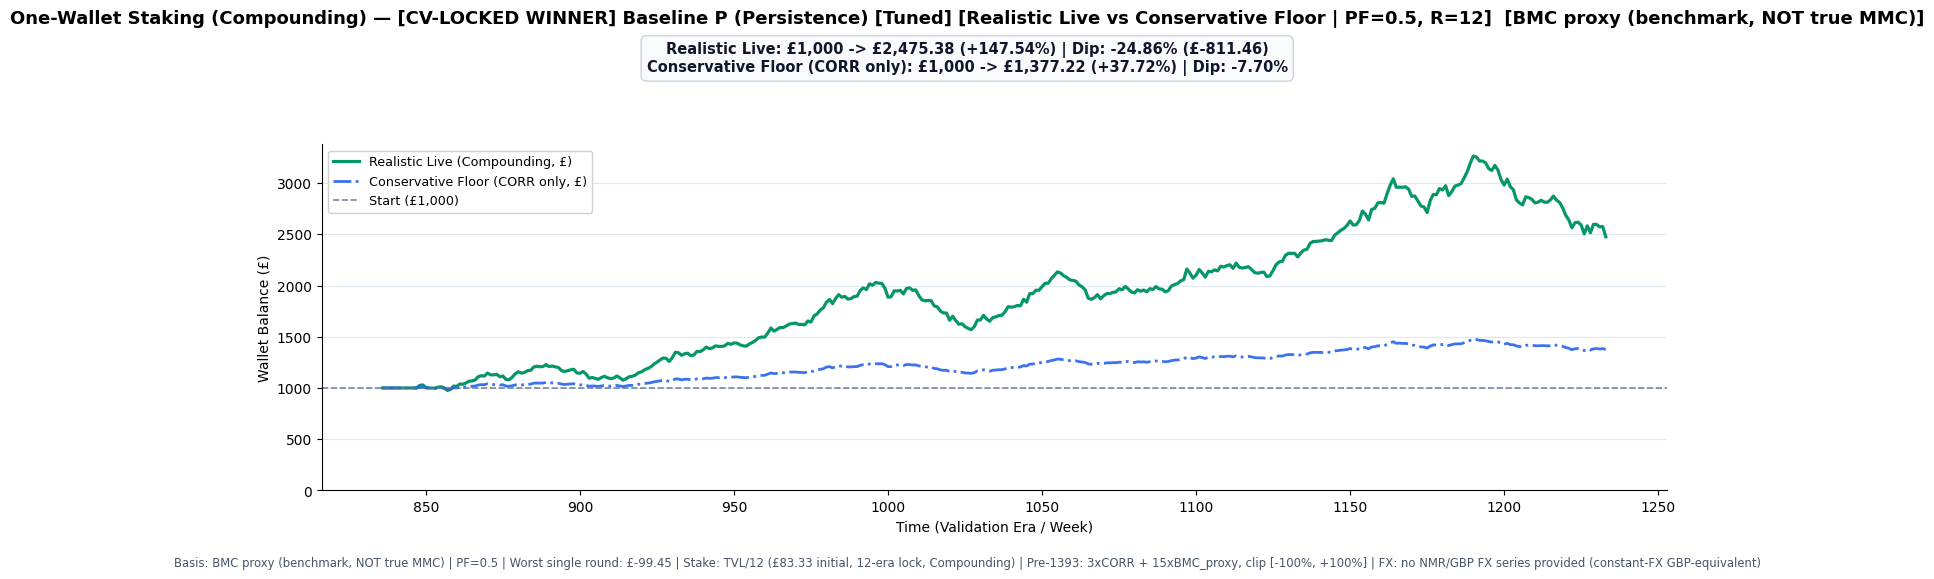

[CV-LOCKED WINNER] Baseline P (Persistence) [Tuned] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £2,475.38 (+147.54%, Dip -24.86%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,377.22 (+37.72%, Dip -7.70%) | Basis: BMC proxy (benchmark, NOT true MMC)


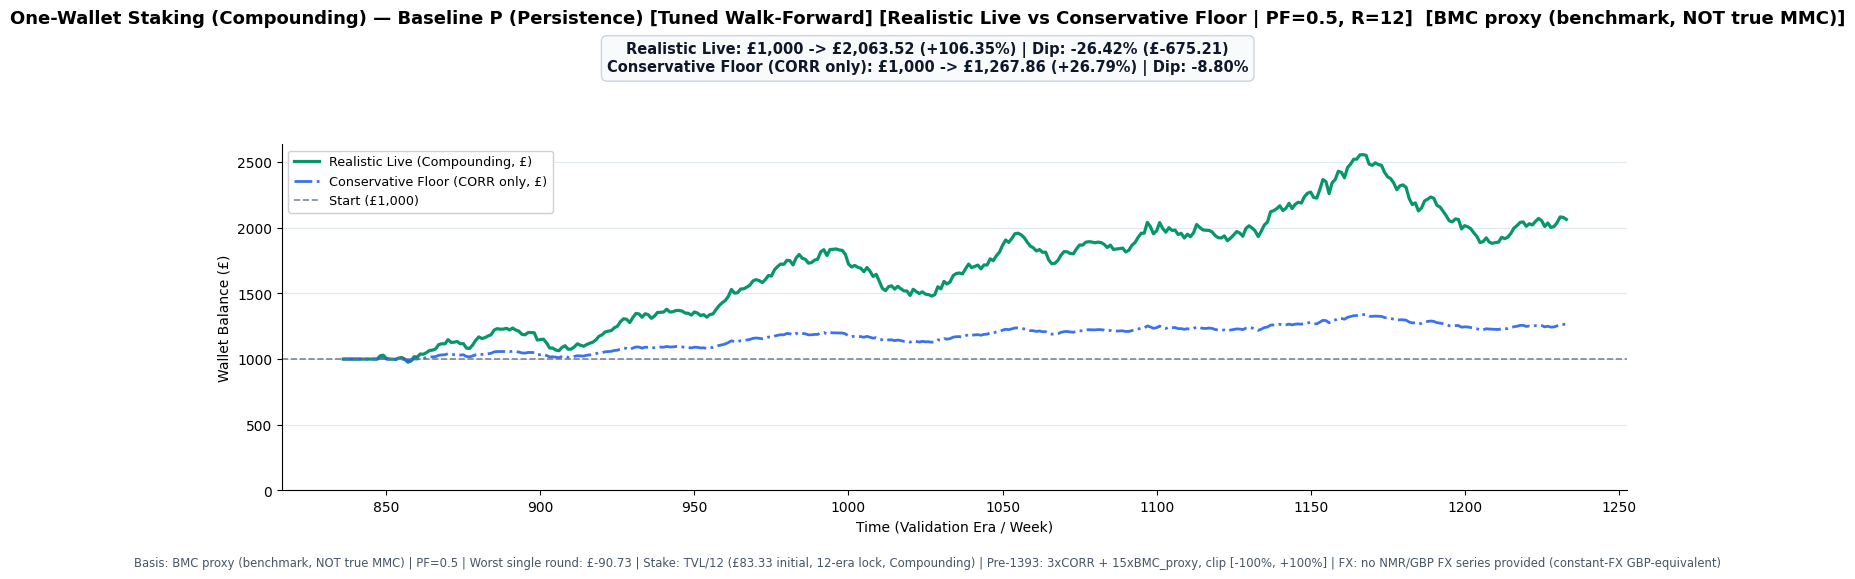

Baseline P (Persistence) [Tuned Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £2,063.52 (+106.35%, Dip -26.42%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,267.86 (+26.79%, Dip -8.80%) | Basis: BMC proxy (benchmark, NOT true MMC)


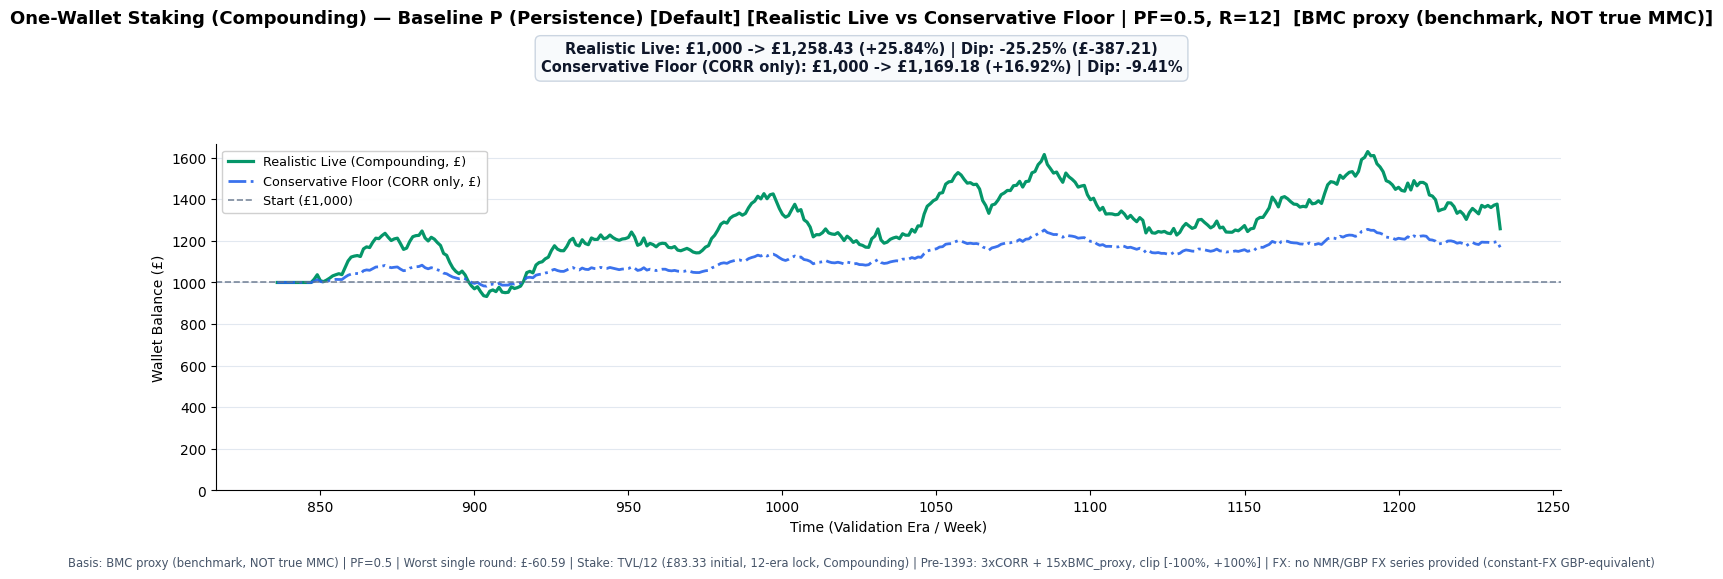

Baseline P (Persistence) [Default] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £1,258.43 (+25.84%, Dip -25.25%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,169.18 (+16.92%, Dip -9.41%) | Basis: BMC proxy (benchmark, NOT true MMC)


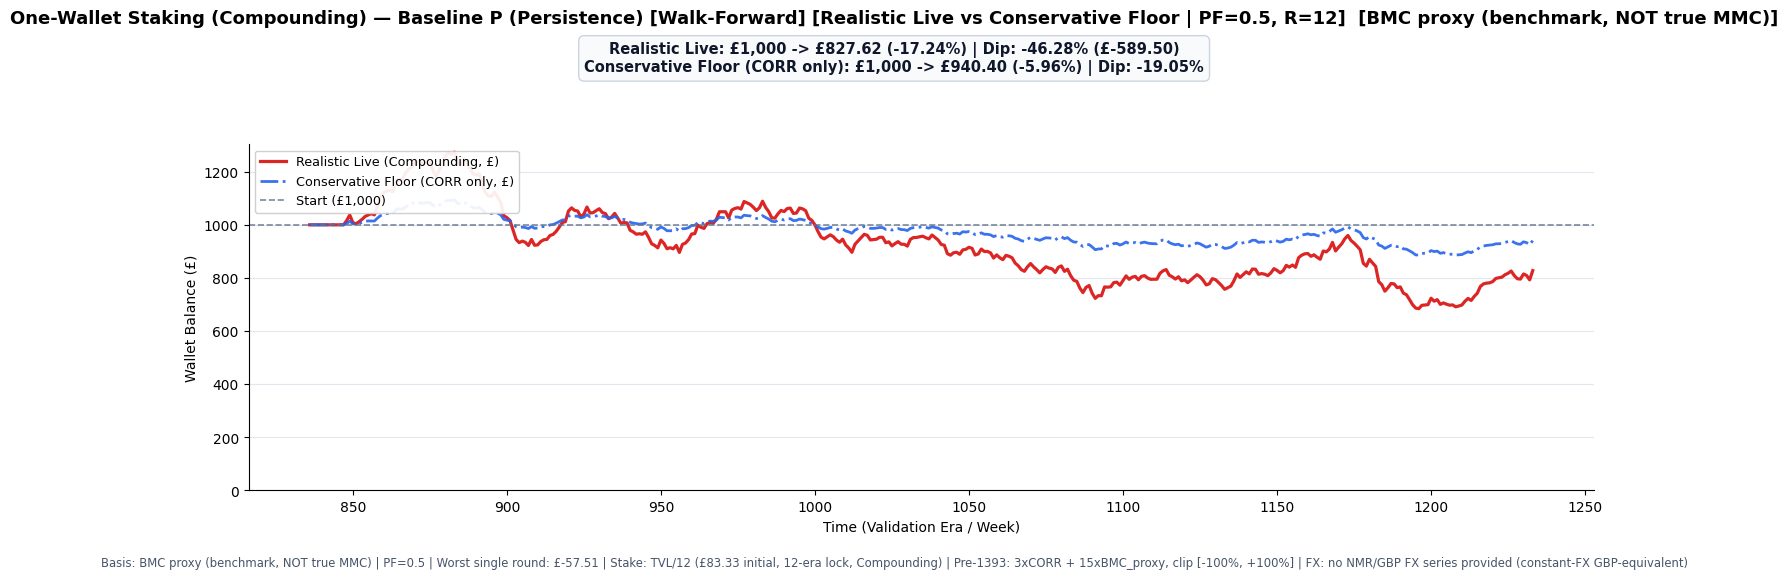

Baseline P (Persistence) [Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £827.62 (-17.24%, Dip -46.28%) | Conservative Floor (CORR only, PF=0.5, R=12): £940.40 (-5.96%, Dip -19.05%) | Basis: BMC proxy (benchmark, NOT true MMC)

Dual-Scenario Realistic Live Staking Table (Conservative Floor [CORR only, PF=0.5, R=12] vs Realistic Live [CORR + 0.5x BMC proxy, PF=0.5, R=12]):


,variant,conservative_end_gbp,conservative_return_pct,conservative_worst_dip_pct,conservative_mc_p_profit_pct,realistic_live_end_gbp,realistic_live_return_pct,realistic_live_worst_dip_pct,realistic_live_mc_p_profit_pct,realistic_live_mc_median_gbp,payout_factor,bmc_haircut,concurrent_rounds
0,Baseline P (Persistence) [Tuned],1377.22,37.72,-7.70,99.2,2475.38,147.54,-24.86,98.0,2533.51,0.5,0.5,12
1,Baseline P (Persistence) [Tuned Walk-Forward],1267.86,26.79,-8.80,95.8,2063.52,106.35,-26.42,95.6,2122.43,0.5,0.5,12
2,Baseline P (Persistence) [Default],1169.18,16.92,-9.41,84.6,1258.43,25.84,-25.25,71.6,1314.06,0.5,0.5,12
3,Baseline P (Persistence) [Walk-Forward],940.40,-5.96,-19.05,36.4,827.62,-17.24,-46.28,36.4,835.83,0.5,0.5,12


In [18]:
val_mmc_df = val_diag_meta.assign(**{TARGET_COL: y_validation.to_numpy(dtype=np.float32)})
staking_basis_label = v6_contrib_info['basis_label']
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
print(f"Active Staking Basis: {staking_basis_label}")
print(f"  -> Reason: {v6_contrib_info['reason']}")

stake_pnl_by_variant = {}
variant_era_mmc_by_variant = {}
live_scenarios_by_variant = {}
staking_summary_rows = []
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    variant_era_corrs = baseline_results[variant_name]['validation_era_corrs']
    variant_era_contrib = compute_per_era_mmc(
        val_mmc_df,
        baseline_results[variant_name]['validation_preds'],
        meta_model_path=v6_contrib_info['meta_model_path'],
        benchmark_path=v6_contrib_info['benchmark_path'],
        is_benchmark_proxy=staking_is_proxy,
        era_col=ERA_COL,
        target_col=TARGET_COL,
    )
    variant_era_mmc_by_variant[variant_name] = variant_era_contrib

    live_scenarios_by_variant[variant_name] = simulate_live_staking_scenarios(
        variant_era_corrs,
        per_era_mmc=variant_era_contrib,
        mmc_is_proxy=staking_is_proxy,
        total_capital=1000.0,
        settlement_rounds=12,
        weekly_concurrent_rounds=12,
        conservative_payout_factor=0.5,
        live_payout_factor=0.5,
        bmc_proxy_haircut=0.5,
        n_sims=500,
        block_size=12,
        random_state=random_state,
        title=variant_name,
        era_dates=val_era_dates,
    )

    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    pnl_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_stake_pnl_dashboard.png'
        if save_results
        else None
    )
    haircutted_contrib = (
        pd.Series(variant_era_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if variant_era_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    stake_pnl_by_variant[variant_name] = plot_stake_pnl_dashboard(
        variant_era_corrs,
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        conservative_pnl=live_scenarios_by_variant[variant_name]['conservative_floor']['pnl'],
        title=f'{title_label} [Realistic Live vs Conservative Floor | PF=0.5, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        era_dates=val_era_dates,
        save_path=pnl_save_path,
    )

    v_pnl = stake_pnl_by_variant[variant_name]
    c_pnl = live_scenarios_by_variant[variant_name]['conservative_floor']['pnl']
    mean_contrib = float(variant_era_contrib.mean()) if variant_era_contrib is not None and len(variant_era_contrib) > 0 else np.nan
    contrib_col_name = 'validation_bmc_proxy' if staking_is_proxy else 'validation_true_mmc'
    staking_summary_rows.append({
        'variant': variant_name,
        'staking_basis': v_pnl['score_basis'],
        'staking_mode': 'One-Wallet (Compounding, PF=0.5, R=12)',
        'validation_corr': round(float(variant_era_corrs.mean()), 4),
        contrib_col_name: round(mean_contrib, 4) if np.isfinite(mean_contrib) else np.nan,
        'start_capital': round(float(v_pnl['start_capital']), 2),
        'end_capital': round(float(v_pnl['end_capital']), 2),
        'total_return_pct': round(float(v_pnl['total_return_pct']), 2),
        'worst_dip_pct': round(float(v_pnl['money_drawdown_pct']), 2),
        'worst_dip_gbp': round(float(v_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(v_pnl['worst_round_gbp']), 2),
    })
    print(
        f"{title_label} | Realistic Live (PF=0.5, 0.5x BMC, R=12): £{v_pnl['end_capital']:,.2f} ({v_pnl['total_return_pct']:+.2f}%, Dip {v_pnl['money_drawdown_pct']:.2f}%) | "
        f"Conservative Floor (CORR only, PF=0.5, R=12): £{c_pnl['end_capital']:,.2f} ({c_pnl['total_return_pct']:+.2f}%, Dip {c_pnl['money_drawdown_pct']:.2f}%) | "
        f"Basis: {v_pnl['score_basis']}"
    )

staking_comparison_df = pd.DataFrame(staking_summary_rows)
live_staking_scenarios_df = build_live_staking_scenarios_df(live_scenarios_by_variant)
comparison_df['staking_basis'] = comparison_df['variant'].map(
    staking_comparison_df.set_index('variant')['staking_basis']
)
if staking_is_proxy:
    comparison_df['validation_bmc_proxy'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_bmc_proxy']
    )
elif v6_contrib_info['basis_kind'] == 'true_mmc':
    comparison_df['validation_true_mmc'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_true_mmc']
    )
print('\nDual-Scenario Realistic Live Staking Table (Conservative Floor [CORR only, PF=0.5, R=12] vs Realistic Live [CORR + 0.5x BMC proxy, PF=0.5, R=12]):')
display(live_staking_scenarios_df)
best_stake_pnl = stake_pnl_by_variant[best_variant_name]

## Monte Carlo Block-Bootstrap Risk Analysis (£)


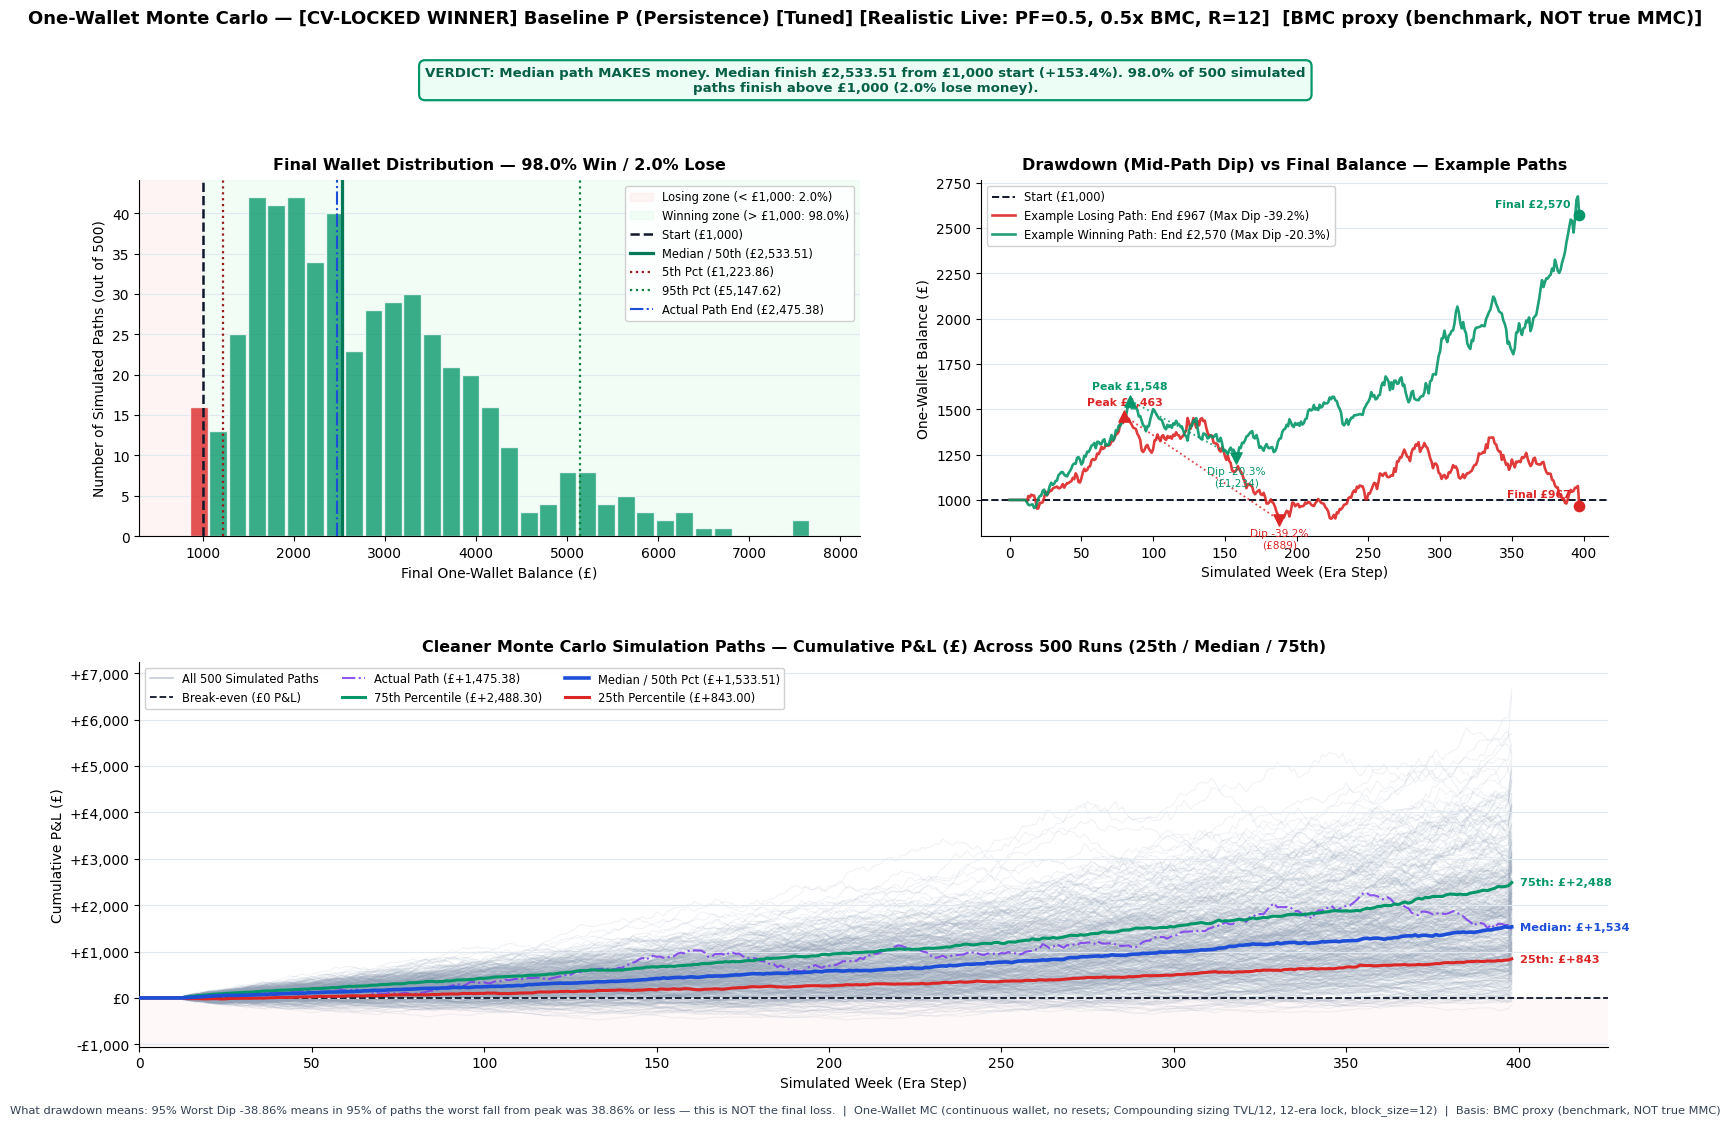

[CV-LOCKED WINNER] Baseline P (Persistence) [Tuned] — VERDICT: Median path MAKES money. Median finish £2,533.51 from £1,000 start (+153.4%). 98.0% of 500 simulated paths finish above £1,000 (2.0% lose money).

How to read Drawdown vs Final Balance (Plain English):
  • Drawdown is the biggest peak-to-trough dip DURING the journey — NOT your final profit or loss.
  • Worked example (Winning path with a drawdown): Start £1,000 -> rises to £1,200 peak -> dips to £1,100 (-8.3% drawdown from peak) -> recovers to £1,300. You still finish +£300 ABOVE £1,000 despite the dip.
  • Worked example (Losing path with a small drawdown): Start £1,000 -> drifts down to £955 (-4.5% dip) and ends at £984.81. A small drawdown still finishes BELOW £1,000 if it never recovers.
  • Median (50th) vs 95th percentile are DIFFERENT paths: Median = typical path; 95th = lucky top 5% of paths.
  • One-Wallet MC: Simulates ONE continuous wallet from start to finish over the full validation period with no resets.
  • 

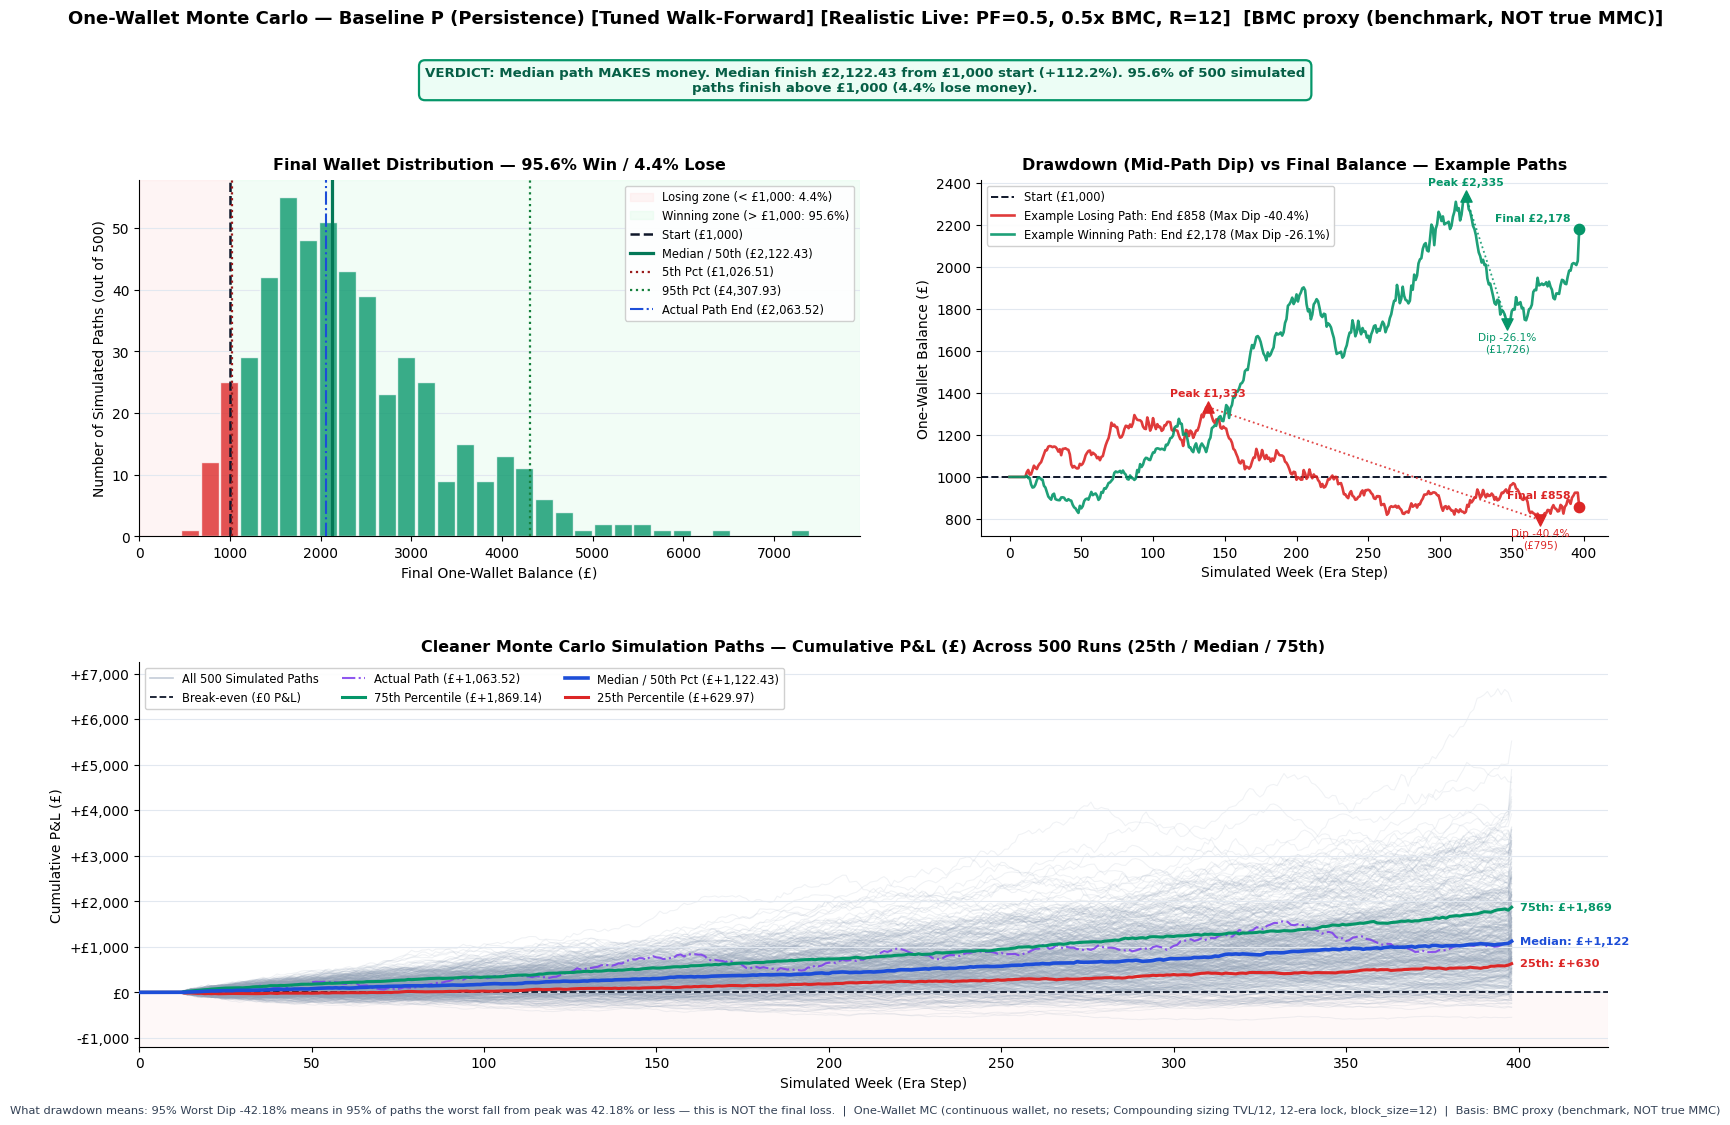

Baseline P (Persistence) [Tuned Walk-Forward] — VERDICT: Median path MAKES money. Median finish £2,122.43 from £1,000 start (+112.2%). 95.6% of 500 simulated paths finish above £1,000 (4.4% lose money).

Baseline P (Persistence) [Tuned Walk-Forward] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 95.6% (4.4% lose) | Median (50th): £2,122.43 (+112.2%) | 5th Pct: £1,026.51 | 95th Pct: £4,307.93 | 95% Worst Dip: -42.18% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -42.18% means in 95% of paths the worst fall from peak was 42.18% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=95.8% | Median=£1,275.71 | 95% Worst Dip=-15.57%


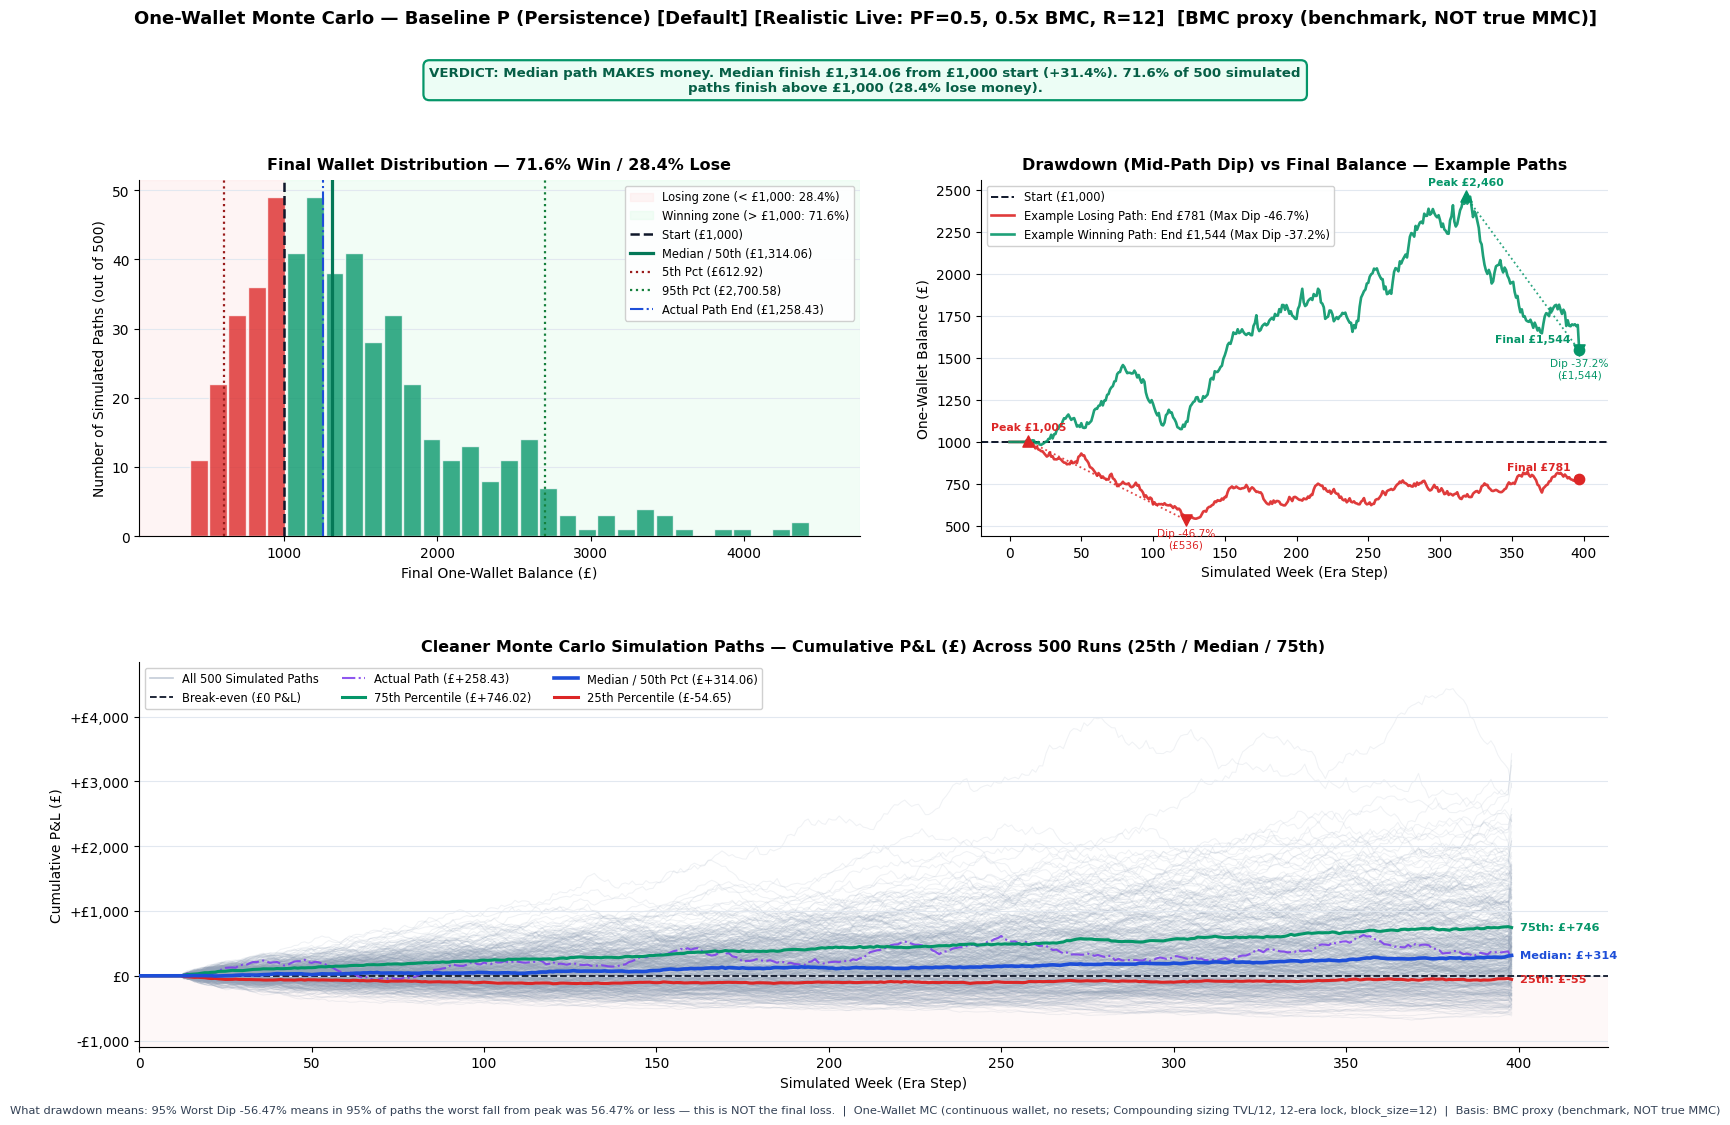

Baseline P (Persistence) [Default] — VERDICT: Median path MAKES money. Median finish £1,314.06 from £1,000 start (+31.4%). 71.6% of 500 simulated paths finish above £1,000 (28.4% lose money).

Baseline P (Persistence) [Default] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 71.6% (28.4% lose) | Median (50th): £1,314.06 (+31.4%) | 5th Pct: £612.92 | 95th Pct: £2,700.58 | 95% Worst Dip: -56.47% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -56.47% means in 95% of paths the worst fall from peak was 56.47% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=84.6% | Median=£1,176.22 | 95% Worst Dip=-20.67%


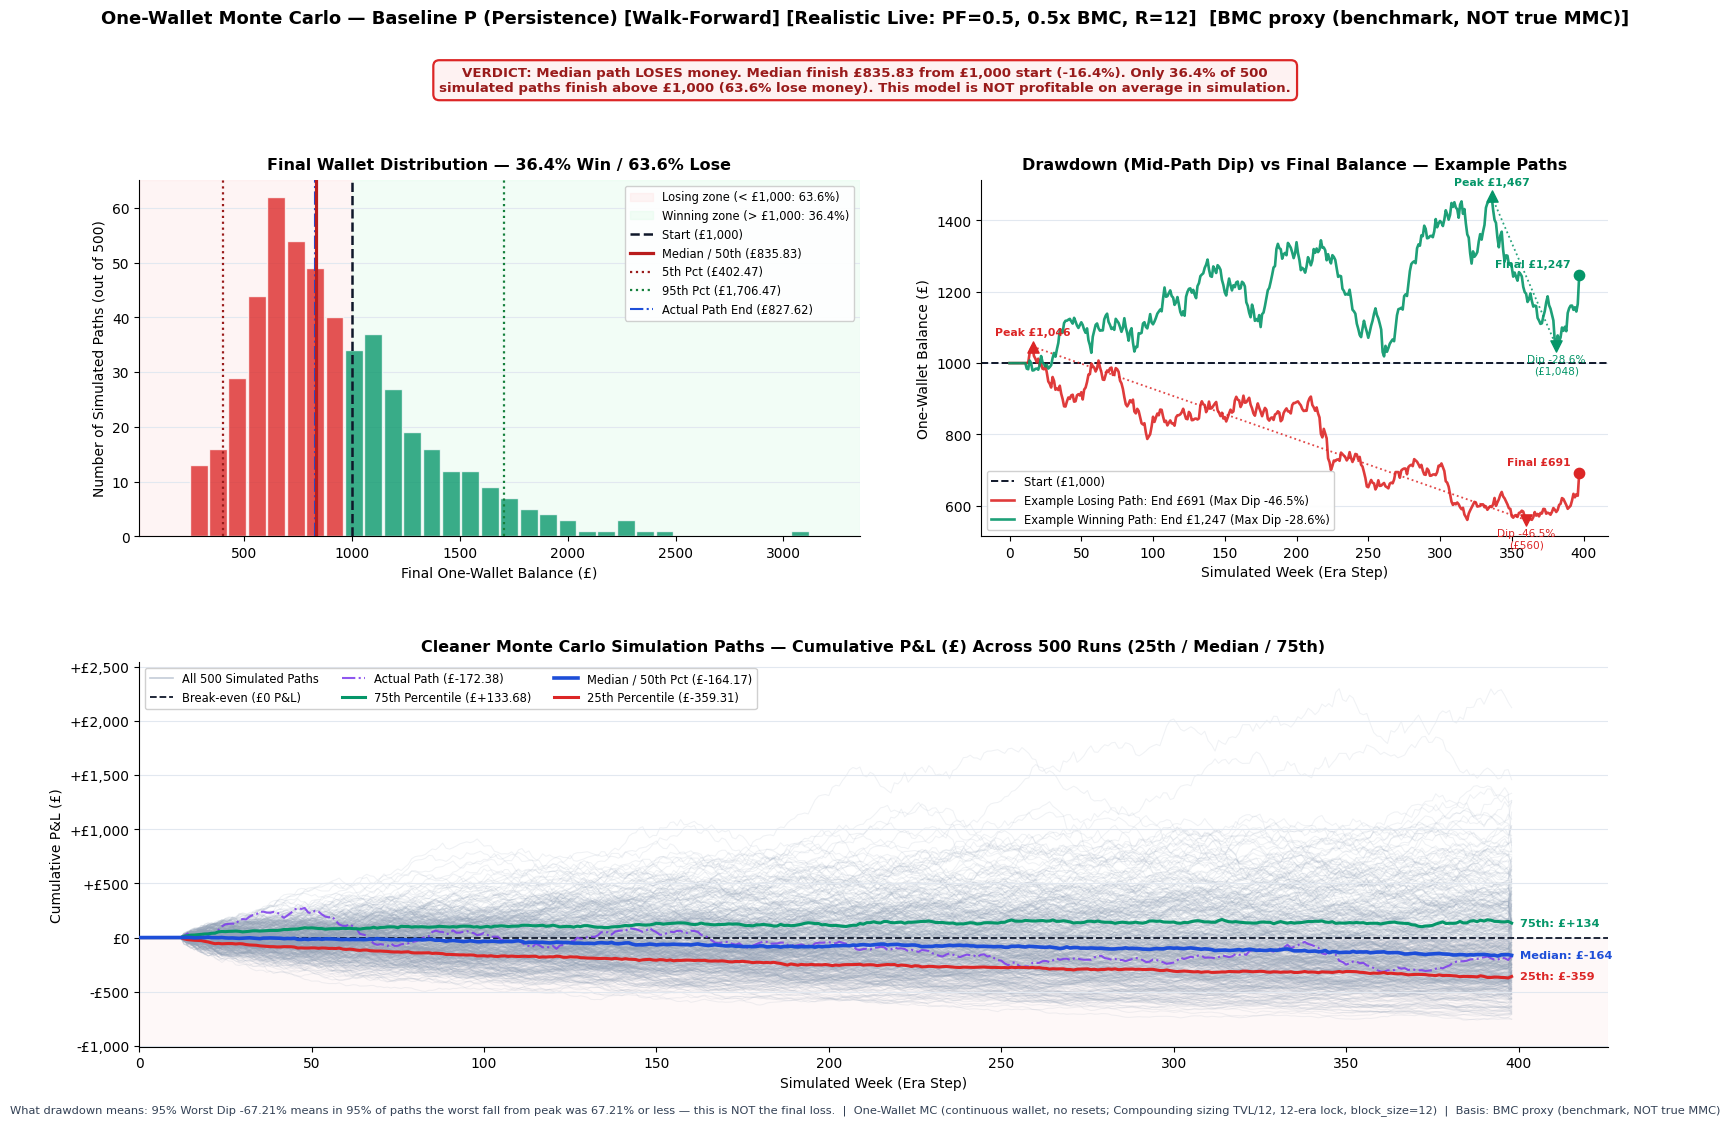

Baseline P (Persistence) [Walk-Forward] — VERDICT: Median path LOSES money. Median finish £835.83 from £1,000 start (-16.4%). Only 36.4% of 500 simulated paths finish above £1,000 (63.6% lose money). This model is NOT profitable on average in simulation.

Baseline P (Persistence) [Walk-Forward] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 36.4% (63.6% lose) | Median (50th): £835.83 (-16.4%) | 5th Pct: £402.47 | 95th Pct: £1,706.47 | 95% Worst Dip: -67.21% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -67.21% means in 95% of paths the worst fall from peak was 67.21% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=36.4% | Median=£947.93 | 95% Worst Dip=-30.60%


In [19]:
mc_risk_by_variant = {}
explainer_printed = False
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    mc_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_monte_carlo_pnl.png'
        if save_results
        else None
    )
    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    raw_contrib = variant_era_mmc_by_variant.get(variant_name)
    haircutted_contrib = (
        pd.Series(raw_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if raw_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    v_mc = plot_stake_pnl_monte_carlo(
        baseline_results[variant_name]['validation_era_corrs'],
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        title=f'{title_label} [Realistic Live: PF=0.5, 0.5x BMC, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        n_sims=500,
        block_size=12,
        random_state=random_state,
        era_dates=val_era_dates,
        save_path=mc_save_path,
    )
    mc_risk_by_variant[variant_name] = v_mc
    c_mc = live_scenarios_by_variant[variant_name]['conservative_floor']['mc']
    print('=' * 100)
    print(f"{title_label} — {v_mc['mc_verdict_text']}")
    if not explainer_printed:
        print()
        print(v_mc['mc_explainer_text'])
        explainer_printed = True
    print()
    print(v_mc['mc_summary_line'])
    print(f"  -> {v_mc['mc_drawdown_explanation_line']}")
    print(
        f"  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)={c_mc['mc_prob_profit_pct']:.1f}% | "
        f"Median=£{c_mc['mc_median_final_stake']:,.2f} | 95% Worst Dip={c_mc['mc_p95_money_drawdown_pct']:.2f}%"
    )
    print('=' * 100)

## Optional Community Companion: `numereval` (Council of Elders)
Runs `councilofelders/numereval` alongside official `numerai-tools` metrics when installed locally (skips gracefully on Kaggle if unavailable). **Note:** `numereval` uses classic Spearman diagnostics and is not the official v6.0 Unity `NCORR` / `NMMC` / staking calculation.

In [20]:
numereval_summary_df = run_numereval_diagnostics(
    y_validation,
    baseline_results[best_variant_name]['validation_preds'],
    validation_eras,
    variant_name=best_variant_name,
    plot=False,
    verbose=True,
)
if numereval_summary_df is not None:
    display(numereval_summary_df)

[numereval companion] Not installed in this environment (optional). Install with: pip install --no-deps git+https://github.com/councilofelders/numereval.git
